In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)

BASE = "/kaggle/input/datasets/ayamoujoud13/cresci"
LABELS = {"E13.csv": 0, "TFP.csv": 0, "FSF.csv": 1, "INT.csv": 1, "TWT.csv": 1}

frames = []
for folder, label in LABELS.items():
    df = pd.read_csv(os.path.join(BASE, folder, "users.csv"),
                     encoding="latin-1", low_memory=False)
    df["label"] = label
    df["source_set"] = folder.replace(".csv", "")
    frames.append(df)
raw = pd.concat(frames, ignore_index=True)

print("Taille brute :", raw.shape)
print("Doublons sur id :", raw.duplicated(subset="id").sum())

# Valeurs manquantes (en %), seulement les colonnes concernées
miss = (raw.isna().mean() * 100).round(1).sort_values(ascending=False)
print("\n% de valeurs manquantes :")
print(miss[miss > 0])

# Types des colonnes
print("\nTypes :")
print(raw.dtypes.value_counts())

Taille brute : (5301, 36)
Doublons sur id : 0

% de valeurs manquantes :
verified                        100.0
protected                       100.0
default_profile_image            99.5
profile_background_tile          85.7
url                              84.9
geo_enabled                      79.3
profile_banner_url               76.0
time_zone                        66.7
utc_offset                       66.7
default_profile                  32.4
location                         22.9
description                      22.9
profile_use_background_image      1.8
dtype: float64

Types :
object     21
float64     8
int64       7
Name: count, dtype: int64


label
faux      3351
humain    1950
Name: count, dtype: int64

Proportion de faux comptes : 63.2 %

 label       faux  humain
source_set              
E13            0    1481
FSF         1169       0
INT         1337       0
TFP            0     469
TWT          845       0


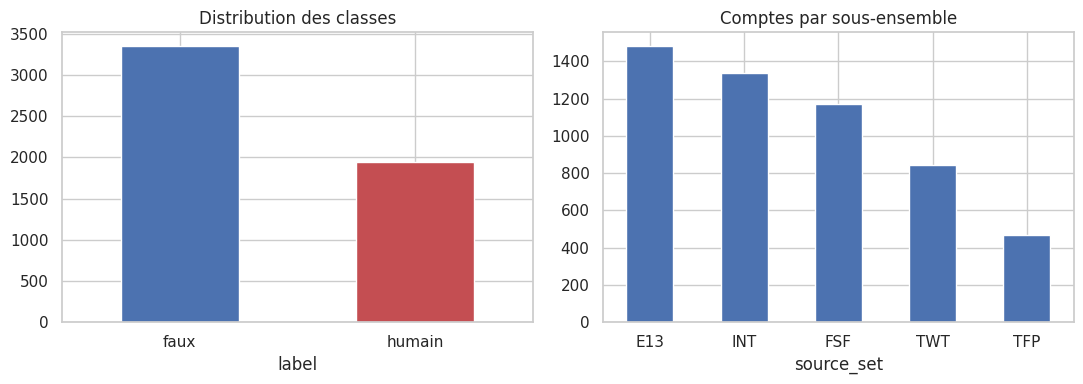

In [2]:
raw = raw.drop_duplicates(subset="id").reset_index(drop=True)

# Équilibre des classes
counts = raw["label"].map({0: "humain", 1: "faux"}).value_counts()
print(counts)
print("\nProportion de faux comptes :", round(raw["label"].mean() * 100, 1), "%")

# Répartition par sous-ensemble
print("\n", pd.crosstab(raw["source_set"], raw["label"].map({0: "humain", 1: "faux"})))

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
counts.plot(kind="bar", ax=ax[0], color=["#4C72B0", "#C44E52"], rot=0)
ax[0].set_title("Distribution des classes")
raw["source_set"].value_counts().plot(kind="bar", ax=ax[1], rot=0)
ax[1].set_title("Comptes par sous-ensemble")
plt.tight_layout(); plt.show()

In [3]:
def to_dt(s):
    return pd.to_datetime(s, errors="coerce", utc=True, format="mixed")

created = to_dt(raw["created_at"])
updated = to_dt(raw["updated"])
ref_date = updated.fillna(updated.max())

eda = pd.DataFrame({
    "label": raw["label"],
    "source_set": raw["source_set"],
    "account_age_days": (ref_date - created).dt.days,
    "n_followers": raw["followers_count"],
    "n_following": raw["friends_count"],
    "n_posts": raw["statuses_count"],
    "n_favourites": raw["favourites_count"],
    "n_listed": raw["listed_count"],
})
age = eda["account_age_days"].clip(lower=1)
eda["posts_per_day"]  = eda["n_posts"] / age
eda["follower_ratio"] = eda["n_followers"] / (eda["n_following"] + 1)

for col, new in [("description", "has_description"), ("url", "has_url"),
                 ("location", "has_location"), ("profile_banner_url", "has_banner")]:
    eda[new] = raw[col].notna().astype(int)
eda["description_len"] = raw["description"].fillna("").astype(str).str.len()
eda["default_profile_image"] = raw["default_profile_image"].fillna(0).astype(int)
eda["default_profile"] = raw["default_profile"].fillna(0).astype(int)
eda["geo_enabled"] = raw["geo_enabled"].fillna(0).astype(int)
eda["verified"] = raw["verified"].fillna(0).astype(int)

sn = raw["screen_name"].fillna("").astype(str)
eda["username_len"] = sn.str.len()
eda["username_digit_ratio"] = sn.apply(lambda s: sum(c.isdigit() for c in s) / max(len(s), 1))

num_cols = ["account_age_days", "n_followers", "n_following", "n_posts",
            "n_favourites", "n_listed", "posts_per_day", "follower_ratio",
            "description_len", "username_len", "username_digit_ratio"]
bin_cols = ["has_description", "has_url", "has_location", "has_banner",
            "default_profile_image", "default_profile", "geo_enabled", "verified"]

print(eda[num_cols].describe().T.round(2))

                       count     mean      std    min     25%     50%  \
account_age_days      5301.0  1175.80   461.20  654.0  747.00  965.00   
n_followers           5301.0   245.64  5879.12    0.0   10.00   18.00   
n_following           5301.0   385.79   560.87    0.0  196.00  274.00   
n_posts               5301.0  1176.74  4488.12    0.0   20.00   39.00   
n_favourites          5301.0   140.93  1093.87    0.0    0.00    0.00   
n_listed              5301.0     2.76    24.85    0.0    0.00    0.00   
posts_per_day         5301.0     0.79     2.92    0.0    0.02    0.04   
follower_ratio        5301.0     0.83    29.20    0.0    0.04    0.06   
description_len       5301.0    64.93    56.11    0.0    8.00   54.00   
username_len          5301.0    11.42     2.75    4.0    9.00   12.00   
username_digit_ratio  5301.0     0.04     0.11    0.0    0.00    0.00   

                          75%        max  
account_age_days      1448.00    3001.00  
n_followers             60.00  408372

label                 médiane faux  médiane humain
account_age_days            964.00         1301.50
n_followers                  12.00           95.00
n_following                 305.00          210.00
n_posts                      23.00          875.00
n_favourites                  0.00           21.00
n_listed                      0.00            1.00
posts_per_day                 0.03            0.67
follower_ratio                0.04            0.45
description_len              38.00           76.00
username_len                 12.00           11.00
username_digit_ratio          0.00            0.00


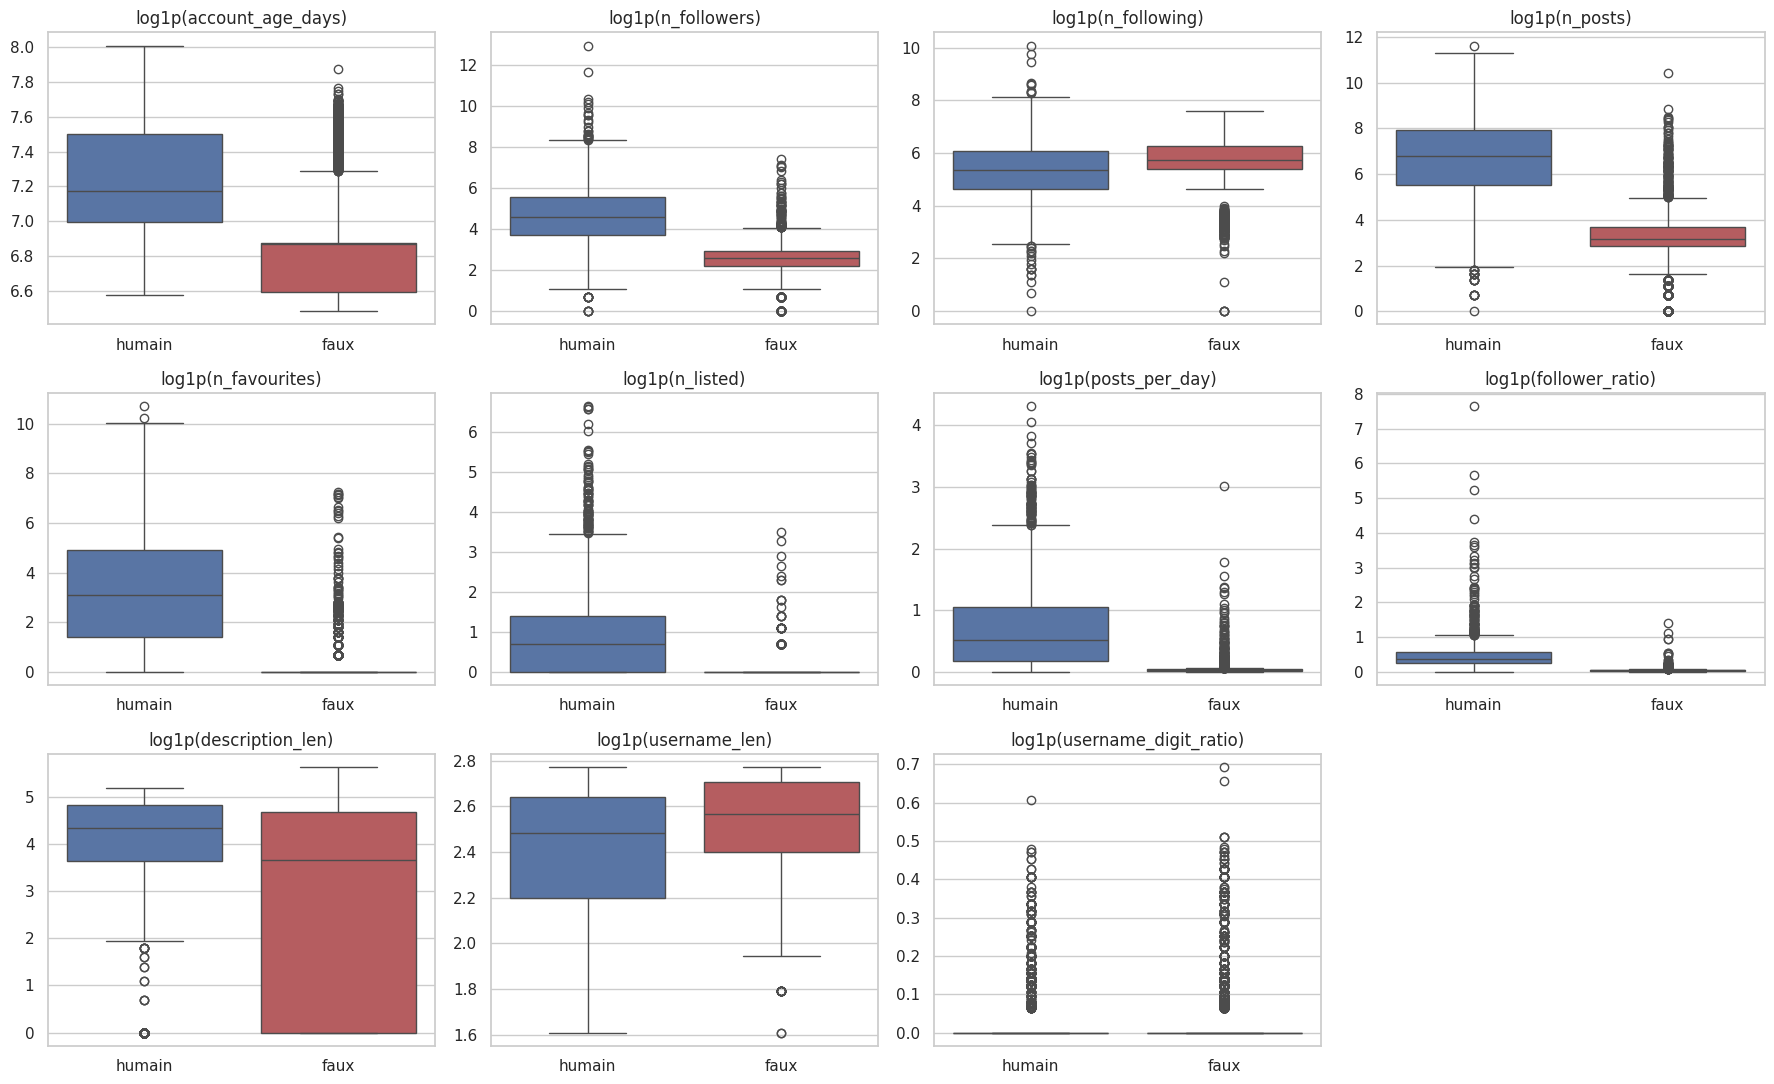

In [4]:
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

lab = eda["label"].map({0: "humain", 1: "faux"})

# Médianes par classe
print(eda.groupby(lab)[num_cols].median().T.round(2).rename(columns=lambda c: f"médiane {c}"))

# Boxplots (échelle log1p car les distributions sont très asymétriques)
plot_df = eda.copy()
plot_df["classe"] = lab

fig, axes = plt.subplots(3, 4, figsize=(18, 11))
for ax, col in zip(axes.ravel(), num_cols):
    plot_df["val"] = np.log1p(plot_df[col].clip(lower=0))
    sns.boxplot(data=plot_df, x="classe", y="val", hue="classe",
                palette=["#4C72B0", "#C44E52"], legend=False, ax=ax)
    ax.set_title(f"log1p({col})"); ax.set_xlabel(""); ax.set_ylabel("")
for ax in axes.ravel()[len(num_cols):]:
    ax.axis("off")
plt.tight_layout(); plt.show()

label                   faux  humain
has_description        0.680   0.927
has_url                0.030   0.357
has_location           0.828   0.673
has_banner             0.020   0.618
default_profile_image  0.002   0.010
default_profile        0.905   0.283
geo_enabled            0.041   0.491
verified               0.000   0.000


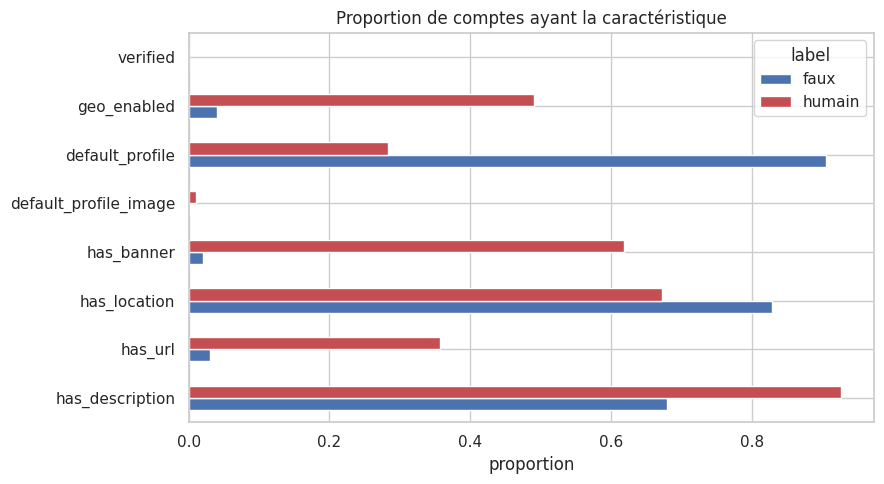

In [5]:
rates = eda.groupby(lab)[bin_cols].mean().T.round(3)
print(rates)

rates.plot(kind="barh", figsize=(9, 5), color=["#4C72B0", "#C44E52"])
plt.title("Proportion de comptes ayant la caractéristique")
plt.xlabel("proportion"); plt.tight_layout(); plt.show()

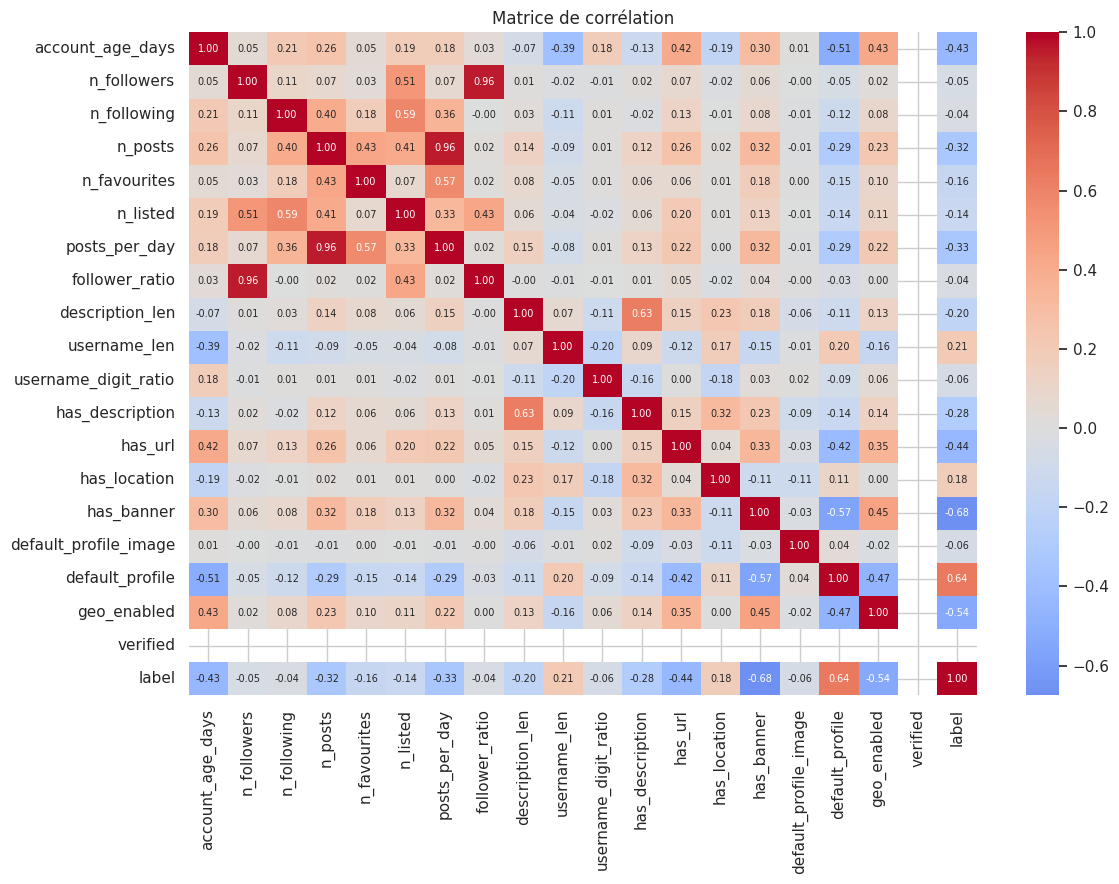

Corrélation avec le label :
has_banner              -0.675
default_profile          0.641
geo_enabled             -0.535
has_url                 -0.441
account_age_days        -0.435
posts_per_day           -0.331
n_posts                 -0.323
has_description         -0.283
username_len             0.207
description_len         -0.203
has_location             0.178
n_favourites            -0.164
n_listed                -0.142
default_profile_image   -0.056
username_digit_ratio    -0.055
n_followers             -0.051
n_following             -0.037
follower_ratio          -0.035
verified                   NaN
Name: label, dtype: float64

% de valeurs extrêmes (IQR) par variable :
  account_age_days            1.0 %
  n_followers                15.4 %
  n_following                 4.1 %
  n_posts                    16.9 %
  n_favourites               19.2 %
  n_listed                   21.7 %
  posts_per_day              17.3 %
  follower_ratio              9.3 %
  description_len      

In [6]:
# Corrélations
corr = eda[num_cols + bin_cols + ["label"]].corr()
plt.figure(figsize=(12, 9))
sns.heatmap(corr, cmap="coolwarm", center=0, annot=True, fmt=".2f",
            annot_kws={"size": 7})
plt.title("Matrice de corrélation"); plt.tight_layout(); plt.show()

print("Corrélation avec le label :")
print(corr["label"].drop("label").sort_values(key=abs, ascending=False).round(3))

# Valeurs extrêmes (méthode IQR)
print("\n% de valeurs extrêmes (IQR) par variable :")
for c in num_cols:
    q1, q3 = eda[c].quantile([0.25, 0.75])
    iqr = q3 - q1
    out = ((eda[c] < q1 - 1.5 * iqr) | (eda[c] > q3 + 1.5 * iqr)).mean() * 100
    print(f"  {c:25s} {out:5.1f} %")

            label               created_min               created_max  \
source_set                                                              
E13             0 2007-04-06 10:58:22+00:00 2013-02-25 20:37:51+00:00   
FSF             1 2013-01-25 20:18:39+00:00 2013-02-13 18:04:04+00:00   
INT             1 2009-05-03 07:35:13+00:00 2013-04-30 12:47:51+00:00   
TFP             0 2006-11-26 15:19:32+00:00 2013-02-04 10:46:05+00:00   
TWT             1 2007-12-07 13:57:04+00:00 2013-03-19 19:19:32+00:00   

                         updated_min               updated_max  
source_set                                                      
E13        2015-02-14 10:54:49+00:00 2015-02-14 10:54:49+00:00  
FSF        2015-02-14 10:26:53+00:00 2015-02-14 10:26:53+00:00  
INT        2015-02-14 10:40:01+00:00 2015-02-14 10:40:01+00:00  
TFP        2015-02-14 11:32:57+00:00 2015-02-14 11:32:57+00:00  
TWT        2015-02-14 09:55:39+00:00 2015-02-14 09:55:39+00:00  


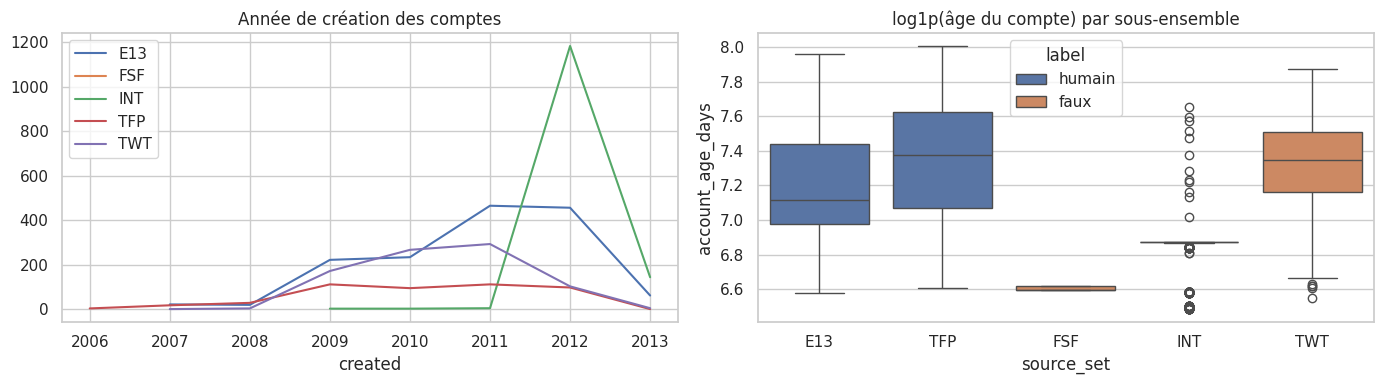

In [7]:
dates = pd.DataFrame({"source_set": raw["source_set"], "label": raw["label"],
                      "created": created, "updated": updated})

print(dates.groupby("source_set").agg(
    label=("label", "first"),
    created_min=("created", "min"), created_max=("created", "max"),
    updated_min=("updated", "min"), updated_max=("updated", "max")))

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
for s, g in dates.groupby("source_set"):
    g["created"].dropna().dt.year.value_counts().sort_index().plot(ax=ax[0], label=s)
ax[0].set_title("Année de création des comptes"); ax[0].legend()
sns.boxplot(data=eda, x="source_set", y=np.log1p(eda["account_age_days"].clip(lower=0)),
            hue=lab, ax=ax[1])
ax[1].set_title("log1p(âge du compte) par sous-ensemble")
plt.tight_layout(); plt.show()

Dossier images : /kaggle/input/datasets/xhlulu/140k-real-and-fake-faces/real_vs_fake/real-vs-fake
train real 50000
train fake 50000
valid real 10000
valid fake 10000
test real 10000
test fake 10000


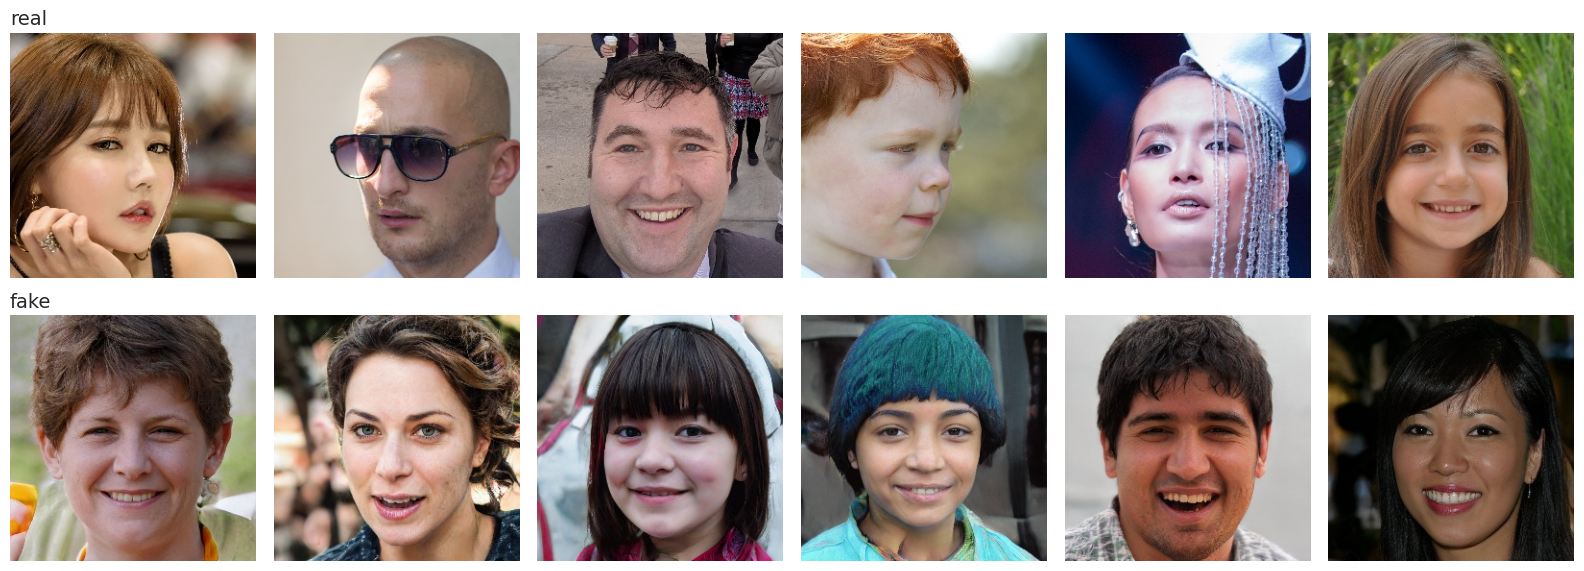

Tailles et modes observés : {((256, 256), 'RGB')}


In [8]:
from PIL import Image
import random

img_base = None
for root, dirs, files in os.walk("/kaggle/input"):
    if root.endswith("train/real"):
        img_base = os.path.dirname(os.path.dirname(root)); break
print("Dossier images :", img_base)

for split in ["train", "valid", "test"]:
    for c in ["real", "fake"]:
        print(split, c, len(os.listdir(f"{img_base}/{split}/{c}")))

# Grille d'exemples
fig, axes = plt.subplots(2, 6, figsize=(16, 6))
for r, c in enumerate(["real", "fake"]):
    d = f"{img_base}/train/{c}"
    for ax, f in zip(axes[r], random.sample(os.listdir(d), 6)):
        ax.imshow(Image.open(f"{d}/{f}")); ax.axis("off")
    axes[r][0].set_title(c, loc="left", fontsize=14)
plt.tight_layout(); plt.show()

# Taille et mode des images (échantillon)
sizes = set()
for f in random.sample(os.listdir(f"{img_base}/train/real"), 50):
    im = Image.open(f"{img_base}/train/real/{f}"); sizes.add((im.size, im.mode))
print("Tailles et modes observés :", sizes)

In [9]:
import os
import pandas as pd

ig_dir = None
for root, dirs, files in os.walk("/kaggle/input"):
    if "instagram" in root.lower() and "train.csv" in files and "test.csv" in files:
        ig_dir = root
        break

assert ig_dir is not None, "Dataset Instagram introuvable : ajoute-le via Add Input (filtre Datasets, auteur free4ever1)."
print("Dossier Instagram :", ig_dir)

ig_train = pd.read_csv(f"{ig_dir}/train.csv")
ig_test  = pd.read_csv(f"{ig_dir}/test.csv")
ig = pd.concat([ig_train, ig_test], ignore_index=True)

assert "fake" in ig.columns, f"Colonne 'fake' absente. Colonnes trouvées : {list(ig.columns)}"

print("Taille :", ig.shape)
print("\nColonnes :", list(ig.columns))
print("\nManquants :", ig.isna().sum().sum())
print("Doublons  :", ig.duplicated().sum())
print("\nClasses :")
print(ig["fake"].map({0: "réel", 1: "faux"}).value_counts())

# Médianes par classe
print("\nMédianes par classe :")
print(ig.groupby(ig["fake"].map({0: "réel", 1: "faux"})).median(numeric_only=True).T.round(2))

# Corrélation avec le label
print("\nCorrélation avec le label :")
print(ig.corr(numeric_only=True)["fake"].drop("fake").sort_values(key=abs, ascending=False).round(3))

Dossier Instagram : /kaggle/input/datasets/free4ever1/instagram-fake-spammer-genuine-accounts
Taille : (696, 12)

Colonnes : ['profile pic', 'nums/length username', 'fullname words', 'nums/length fullname', 'name==username', 'description length', 'external URL', 'private', '#posts', '#followers', '#follows', 'fake']

Manquants : 0
Doublons  : 4

Classes :
fake
réel    348
faux    348
Name: count, dtype: int64

Médianes par classe :
fake                  faux   réel
profile pic            0.0    1.0
nums/length username   0.3    0.0
fullname words         1.0    2.0
nums/length fullname   0.0    0.0
name==username         0.0    0.0
description length     0.0   28.5
external URL           0.0    0.0
private                0.0    0.0
#posts                 0.0   65.0
#followers            43.5  577.0
#follows              76.0  438.0
fake                   1.0    0.0

Corrélation avec le label :
profile pic            -0.625
nums/length username    0.570
description length     -0.479
ext

In [10]:
import numpy as np
import pandas as pd

common = ["profile_pic", "username_digit_ratio", "fullname_words", "name_digit_ratio",
          "name_equals_username", "description_len", "has_url", "private",
          "n_posts", "n_followers", "n_following"]

def digit_ratio(s):
    s = str(s)
    return sum(c.isdigit() for c in s) / max(len(s), 1)

# --- Cresci (Twitter) ---
name = raw["name"].fillna("").astype(str)
sn   = raw["screen_name"].fillna("").astype(str)

cr = pd.DataFrame({
    "profile_pic":          1 - raw["default_profile_image"].fillna(0).astype(int),
    "username_digit_ratio": sn.apply(digit_ratio),
    "fullname_words":       name.str.split().str.len().fillna(0),
    "name_digit_ratio":     name.apply(digit_ratio),
    "name_equals_username": (name.str.lower() == sn.str.lower()).astype(int),
    "description_len":      raw["description"].fillna("").astype(str).str.len(),
    "has_url":              raw["url"].notna().astype(int),
    "private":              raw["protected"].fillna(0).astype(int),
    "n_posts":              raw["statuses_count"],
    "n_followers":          raw["followers_count"],
    "n_following":          raw["friends_count"],
    "label":                raw["label"],
})

# --- Instagram ---
ig_h = ig.drop_duplicates().rename(columns={
    "profile pic": "profile_pic",
    "nums/length username": "username_digit_ratio",
    "fullname words": "fullname_words",
    "nums/length fullname": "name_digit_ratio",
    "name==username": "name_equals_username",
    "description length": "description_len",
    "external URL": "has_url",
    "private": "private",
    "#posts": "n_posts",
    "#followers": "n_followers",
    "#follows": "n_following",
    "fake": "label",
})[common + ["label"]]

print("Cresci   :", cr.shape, "| Instagram :", ig_h.shape)

# Médianes côte à côte (label 0 = réel/humain, 1 = faux)
cmp_med = pd.concat({
    "Cresci":    cr.groupby("label")[common].median().T,
    "Instagram": ig_h.groupby("label")[common].median().T,
}, axis=1).round(2)
print("\nMédianes (0 = réel, 1 = faux) :")
print(cmp_med)

# Corrélation de Spearman avec le label, côte à côte
cmp_corr = pd.DataFrame({
    "Cresci":    cr[common + ["label"]].corr(method="spearman")["label"].drop("label"),
    "Instagram": ig_h[common + ["label"]].corr(method="spearman")["label"].drop("label"),
}).round(3)
cmp_corr["même signe ?"] = np.sign(cmp_corr["Cresci"]) == np.sign(cmp_corr["Instagram"])
print("\nCorrélation de Spearman avec le label :")
print(cmp_corr.sort_values("Instagram", key=abs, ascending=False))

Cresci   : (5301, 12) | Instagram : (692, 12)

Médianes (0 = réel, 1 = faux) :
                     Cresci        Instagram      
label                     0      1         0     1
profile_pic             1.0    1.0       1.0   0.0
username_digit_ratio    0.0    0.0       0.0   0.3
fullname_words          2.0    2.0       2.0   1.0
name_digit_ratio        0.0    0.0       0.0   0.0
name_equals_username    0.0    0.0       0.0   0.0
description_len        76.0   38.0      28.0   0.0
has_url                 0.0    0.0       0.0   0.0
private                 0.0    0.0       0.0   0.0
n_posts               875.0   23.0      65.0   0.0
n_followers            95.0   12.0     573.0  43.0
n_following           210.0  305.0     438.0  76.0

Corrélation de Spearman avec le label :
                      Cresci  Instagram  même signe ?
n_posts               -0.734     -0.726          True
n_followers           -0.691     -0.718          True
profile_pic            0.056     -0.627         False
d

In [11]:
import os, warnings, joblib
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.utils.class_weight import compute_class_weight

warnings.filterwarnings("ignore")
SEED = 42
OUT = "/kaggle/working"

# ---------- 1) Chargement Cresci-2017 ----------
BASE = "/kaggle/input/datasets/ayamoujoud13/cresci"
LABELS = {"E13.csv": 0, "TFP.csv": 0, "FSF.csv": 1, "INT.csv": 1, "TWT.csv": 1}

frames = []
for folder, label in LABELS.items():
    df = pd.read_csv(os.path.join(BASE, folder, "users.csv"),
                     encoding="latin-1", low_memory=False)
    df["label"] = label
    df["source_set"] = folder.replace(".csv", "")
    frames.append(df)

# ---------- 1bis) NOUVEAU : Cresci-stock-2018 (users.csv de Zenodo) ----------
EXTRA_NAME   = "TWBOT"   # nom du sous-ensemble dans la colonne source_set
EXTRA_CSV    = None      # None = détection automatique ; sinon colle le chemin du users.csv ici
MAX_PER_CLASS = 6000     # nb max de bots et d'humains gardés (assez d'images, entraînement raisonnable)

def find_extra_csv():
    found = []
    for root, _, files in os.walk("/kaggle/input"):
        for f in files:
            p = os.path.join(root, f)
            if f.lower().endswith(".csv") and not p.startswith(BASE + "/") and "instagram" not in p.lower():
                found.append(p)
    stock = [p for p in found if "stock" in p.lower()]
    if len(stock) == 1: return stock[0]
    if len(found) == 1: return found[0]
    raise FileNotFoundError("Mets le bon chemin dans EXTRA_CSV. CSV trouvés : " + str(found))

def _pick(d, names):
    low = {c.lower().strip(): c for c in d.columns}
    for n in names:
        if n in low:
            return d[low[n]]
    return pd.Series(np.nan, index=d.index)

def _num(d, names):
    return pd.to_numeric(_pick(d, names), errors="coerce")

def _to01(s):
    m = {"true": 1, "false": 0, "1": 1, "0": 0, "1.0": 1, "0.0": 0, "yes": 1, "no": 0, "t": 1, "f": 0}
    return s.astype(str).str.strip().str.lower().map(m)

def _to_label(s):
    bot = {"bot", "1", "1.0", "true", "fake", "spam", "spambot", "automated"}
    hum = {"human", "0", "0.0", "false", "real", "genuine", "organic", "normal"}
    t = s.astype(str).str.strip().str.lower()
    return t.map(lambda v: 1 if v in bot else (0 if v in hum else np.nan))

def to_cresci_schema(d):
    """Remet le dataset dans les noms de colonnes de Cresci-2017 (mêmes features)."""
    lab_col = next((c for c in d.columns if c.lower().strip() in
                    ["bot", "account_type", "label", "is_bot", "class", "target", "type"]), None)
    assert lab_col is not None, f"Colonne de label introuvable. Colonnes : {list(d.columns)}"
    ex = pd.DataFrame({
        "id":                    _num(d, ["id", "user_id", "id_str"]),
        "name":                  _pick(d, ["name", "display_name", "fullname", "full_name"]),
        "screen_name":           _pick(d, ["screen_name", "username", "user_name", "handle"]),
        "created_at":            _pick(d, ["created_at", "account_created_at", "creation_date"]),
        "description":           _pick(d, ["description", "bio", "profile_description"]),
        "url":                   _pick(d, ["url", "external_url"]),
        "location":              _pick(d, ["location"]),
        "profile_banner_url":    _pick(d, ["profile_banner_url"]),
        "default_profile_image": _to01(_pick(d, ["default_profile_image"])),
        "default_profile":       _to01(_pick(d, ["default_profile"])),
        "geo_enabled":           _to01(_pick(d, ["geo_enabled"])),
        "verified":              _to01(_pick(d, ["verified"])),
        "protected":             _to01(_pick(d, ["protected"])),
        "statuses_count":        _num(d, ["statuses_count", "tweet_count", "tweets_count", "tweets", "posts"]),
        "followers_count":       _num(d, ["followers_count", "followers"]),
        "friends_count":         _num(d, ["friends_count", "following_count", "following", "friends"]),
        "favourites_count":      _num(d, ["favourites_count", "favorites_count", "favourites", "likes"]),
        "listed_count":          _num(d, ["listed_count", "listed"]),
        "label":                 _to_label(d[lab_col]),
    })
    ex["id"] = ex["id"].fillna(pd.Series(-np.arange(1, len(ex) + 1), index=ex.index))
    cdt = pd.to_datetime(ex["created_at"], errors="coerce", utc=True, format="mixed")
    age = _num(d, ["account_age_days", "account_age"])
    if age.notna().any():
        ex["updated"] = (cdt + pd.to_timedelta(age, unit="D")).astype(str)
    else:
        ex["updated"] = str(cdt.max())          # date de collecte approximée
    ex["created_at"] = cdt.astype(str)
    n_before = len(ex)
    ex = ex.dropna(subset=["label"]).assign(label=lambda x: x["label"].astype(int))
    print(f"  {n_before - len(ex)} comptes sans label (non annotés) retirés, {len(ex)} gardés")
    return ex

extra_path = EXTRA_CSV or find_extra_csv()
print("Dataset ajouté :", extra_path)
try:   # ce fichier est en UTF-8 avec des guillemets échappés par \
    extra_raw = pd.read_csv(extra_path, encoding="utf-8", escapechar="\\", low_memory=False)
except UnicodeDecodeError:
    extra_raw = pd.read_csv(extra_path, encoding="latin-1", escapechar="\\", low_memory=False)
print("  colonnes d'origine :", list(extra_raw.columns), "| lignes :", len(extra_raw))
extra = to_cresci_schema(extra_raw)

# colonnes de profil totalement absentes de ce dataset (seront neutralisées plus bas)
MISSING_MAP = {"default_profile_image": "profile_pic", "default_profile": "default_profile",
               "geo_enabled": "geo_enabled", "profile_banner_url": "has_banner"}
absent = [f for r, f in MISSING_MAP.items() if extra[r].isna().all()]

# échantillon équilibré en taille max par classe
extra = pd.concat([g.sample(min(len(g), MAX_PER_CLASS), random_state=SEED)
                   for _, g in extra.groupby("label")], ignore_index=True)
extra["source_set"] = EXTRA_NAME
print(f"  gardés : {len(extra)} comptes | bots = {extra['label'].mean()*100:.1f} %")
frames.append(extra)

raw = (pd.concat(frames, ignore_index=True)
         .drop_duplicates(subset="id").reset_index(drop=True))
print("Comptes après suppression des doublons :", raw.shape[0])
print(raw.groupby("source_set")["label"].agg(["size", "mean"]).round(3))

# ---------- 2) Features ----------
def digit_ratio(s):
    s = str(s)
    return sum(c.isdigit() for c in s) / max(len(s), 1)

name = raw["name"].fillna("").astype(str)
sn   = raw["screen_name"].fillna("").astype(str)

created = pd.to_datetime(raw["created_at"], errors="coerce", utc=True, format="mixed")
updated = pd.to_datetime(raw["updated"],    errors="coerce", utc=True, format="mixed")
age = (updated.fillna(updated.max()) - created).dt.days
age = age.fillna(age.median()).clip(lower=1)

feat = pd.DataFrame({
    "id": raw["id"], "source_set": raw["source_set"], "label": raw["label"],

    # --- features communes avec Instagram ---
    "profile_pic":          1 - raw["default_profile_image"].fillna(0).astype(int),
    "username_digit_ratio": sn.apply(digit_ratio),
    "fullname_words":       name.str.split().str.len().fillna(0),
    "name_digit_ratio":     name.apply(digit_ratio),
    "name_equals_username": (name.str.lower() == sn.str.lower()).astype(int),
    "description_len":      raw["description"].fillna("").astype(str).str.len(),
    "has_url":              raw["url"].notna().astype(int),
    "n_posts":              raw["statuses_count"],
    "n_followers":          raw["followers_count"],
    "n_following":          raw["friends_count"],

    # --- features propres à Cresci (modèle principal) ---
    "n_favourites":    raw["favourites_count"],
    "n_listed":        raw["listed_count"],
    "has_location":    raw["location"].notna().astype(int),
    "has_banner":      raw["profile_banner_url"].notna().astype(int),
    "default_profile": raw["default_profile"].fillna(0).astype(int),
    "geo_enabled":     raw["geo_enabled"].fillna(0).astype(int),
    "verified":        raw["verified"].fillna(0).astype(int),

    # --- réservées à l'ablation (biais de création en lots) ---
    "account_age_days": age,
    "posts_per_day":    raw["statuses_count"] / age,
})
feat["follower_ratio"] = feat["n_followers"] / (feat["n_following"] + 1)
feat["profile_completeness"] = feat[["has_url", "has_location", "has_banner"]].mean(axis=1)
feat["has_description"] = (feat["description_len"] > 0).astype(int)

# Colonnes que le dataset ajouté ne fournit pas : on met la moyenne des autres sources,
# pour que le modèle ne confonde pas « information absente » avec « valeur 0 ».
if absent:
    m = (feat["source_set"] == EXTRA_NAME).values
    fix = absent + (["profile_completeness"] if "has_banner" in absent else [])
    for c in fix:
        feat[c] = feat[c].astype(float)
        feat.loc[m, c] = feat.loc[~m, c].mean()
    print("Colonnes absentes du dataset ajouté, remplacées par la moyenne des autres sources :", fix)

# ---------- 3) Valeurs manquantes ----------
meta = ["id", "source_set", "label"]
num_all = [c for c in feat.columns if c not in meta]
feat[num_all] = feat[num_all].replace([np.inf, -np.inf], np.nan)
feat[num_all] = feat[num_all].fillna(feat[num_all].median())

# ---------- 4) log1p sur les compteurs ----------
LOG_COLS = ["n_posts", "n_followers", "n_following", "n_favourites", "n_listed",
            "description_len", "follower_ratio", "account_age_days", "posts_per_day"]
for c in LOG_COLS:
    feat[c] = np.log1p(feat[c].clip(lower=0))

# ---------- 5) Liste des features ----------
ABLATION = ["account_age_days", "posts_per_day"]
MAIN = [c for c in num_all if c not in ABLATION]
MAIN = [c for c in MAIN if feat[c].nunique() > 1]       # retire les colonnes constantes
dropped = sorted(set(num_all) - set(MAIN) - set(ABLATION))
print("Colonnes constantes supprimées :", dropped)
print(f"Features principales ({len(MAIN)}) :", MAIN)

# ---------- 6) Split 70 / 15 / 15, stratifié (label + sous-ensemble) ----------
strat = feat["label"].astype(str) + "_" + feat["source_set"]
train, temp = train_test_split(feat, test_size=0.30, stratify=strat, random_state=SEED)
val, test = train_test_split(temp, test_size=0.50,
                             stratify=temp["label"].astype(str) + "_" + temp["source_set"],
                             random_state=SEED)
for n, d in [("train", train), ("val", val), ("test", test)]:
    print(f"{n:5s} : {len(d):5d} comptes | faux = {d['label'].mean()*100:.1f} %")

# ---------- 7) Normalisation : ajustée sur le train seulement ----------
scaler = StandardScaler().fit(train[MAIN])
def scaled(d):
    X = d.copy()
    X[MAIN] = scaler.transform(d[MAIN])
    return X

# ---------- 8) Poids de classe (train) ----------
w = compute_class_weight("balanced", classes=np.array([0, 1]), y=train["label"])
print("Poids de classe (humain, faux) :", w.round(3))

# ---------- 9) Sauvegarde ----------
scaled(train).to_csv(f"{OUT}/profiles_train.csv", index=False)
scaled(val).to_csv(f"{OUT}/profiles_val.csv", index=False)
scaled(test).to_csv(f"{OUT}/profiles_test.csv", index=False)
joblib.dump({"scaler": scaler, "main": MAIN, "ablation": ABLATION,
             "class_weights": w}, f"{OUT}/profile_prep.joblib")
print("\nFichiers sauvegardés dans", OUT)

Dataset ajouté : /kaggle/input/datasets/ayamoujoud13/cresci-stock-2018/users.csv
  colonnes d'origine : ['id', 'name', 'screen_name', 'statuses_count', 'followers_count', 'friends_count', 'favourites_count', 'listed_count', 'url', 'lang', 'time_zone', 'location', 'verified', 'description', 'created_at', 'bot'] | lignes : 597413
  571425 comptes sans label (non annotés) retirés, 25988 gardés
  gardés : 12000 comptes | bots = 50.0 %
Comptes après suppression des doublons : 17301
             size  mean
source_set             
E13          1481   0.0
FSF          1169   1.0
INT          1337   1.0
TFP           469   0.0
TWBOT       12000   0.5
TWT           845   1.0
Colonnes absentes du dataset ajouté, remplacées par la moyenne des autres sources : ['profile_pic', 'default_profile', 'geo_enabled', 'has_banner', 'profile_completeness']
Colonnes constantes supprimées : []
Features principales (20) : ['profile_pic', 'username_digit_ratio', 'fullname_words', 'name_digit_ratio', 'name_equals

In [12]:
import os, random, warnings
import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")
SEED       = 42
NOISE      = 0.15          # proportion de paires "croisées" (image de la classe opposée)
LABEL_RULE = "or"          # "or" : suspect si profil faux OU image fausse | "profile" : label du profil
OUT        = "/kaggle/working"

# ---------- 1) Profils pré-traités (cellule 12) ----------
files = {"train": "profiles_train.csv", "val": "profiles_val.csv", "test": "profiles_test.csv"}
for f in files.values():
    assert os.path.exists(f"{OUT}/{f}"), f"{f} introuvable : relance la cellule 12."
profiles = {s: pd.read_csv(f"{OUT}/{f}") for s, f in files.items()}

# ---------- 2) Dossier des images ----------
img_base = None
for root, dirs, _ in os.walk("/kaggle/input"):
    if {"train", "valid", "test"}.issubset(set(dirs)):
        img_base = root
        break
assert img_base is not None, "Dataset d'images introuvable : ajoute 140k real and fake faces (filtre Datasets)."
print("Dossier images :", img_base)

# profils (train/val/test)  ->  dossier d'images (train/valid/test)
IMG_SPLIT = {"train": "train", "val": "valid", "test": "test"}

def list_images(split, cls):
    d = f"{img_base}/{IMG_SPLIT[split]}/{cls}"
    return sorted(os.path.join(d, f) for f in os.listdir(d))

# ---------- 3) Appariement ----------
rng = np.random.default_rng(SEED)
paired = {}

for split, df in profiles.items():
    df = df.copy().reset_index(drop=True)
    n = len(df)

    # classe de l'image : celle du profil, inversée avec probabilité NOISE
    flip = rng.random(n) < NOISE
    img_label = np.where(flip, 1 - df["label"].values, df["label"].values)   # 1 = image fausse

    df["label_profile"] = df["label"]
    df["label_image"]   = img_label
    df["is_crossed"]    = flip.astype(int)

    # tirage sans remise dans le dossier correspondant
    paths = np.empty(n, dtype=object)
    for lab, cls in [(0, "real"), (1, "fake")]:
        idx = np.where(img_label == lab)[0]
        pool = list_images(split, cls)
        assert len(idx) <= len(pool), f"Pas assez d'images {cls} dans {split}"
        paths[idx] = rng.choice(pool, size=len(idx), replace=False)
    df["image_path"] = paths

    # label d'identité
    if LABEL_RULE == "or":
        df["label"] = ((df["label_profile"] == 1) | (df["label_image"] == 1)).astype(int)
    else:
        df["label"] = df["label_profile"]

    paired[split] = df

# ---------- 4) Vérifications ----------
all_paths = pd.concat([d["image_path"] for d in paired.values()])
print("\nImages utilisées :", len(all_paths), "| uniques :", all_paths.nunique())
assert all_paths.is_unique, "Une image est utilisée plusieurs fois !"

for s, d in paired.items():
    print(f"\n[{s}] {len(d)} paires | croisées : {d['is_crossed'].mean()*100:.1f} % "
          f"| suspects (label final) : {d['label'].mean()*100:.1f} %")
    print(pd.crosstab(d["label_profile"].map({0: "profil humain", 1: "profil faux"}),
                      d["label_image"].map({0: "image réelle", 1: "image fausse"})))

# les images de chaque split viennent bien du bon dossier
for s, d in paired.items():
    ok = d["image_path"].str.contains(f"/{IMG_SPLIT[s]}/").all()
    print(f"[{s}] images toutes issues de '{IMG_SPLIT[s]}' :", ok)

# ---------- 5) Sauvegarde ----------
for s, d in paired.items():
    d.to_csv(f"{OUT}/pairs_{s}.csv", index=False)
print("\nFichiers : pairs_train.csv, pairs_val.csv, pairs_test.csv dans", OUT)
display(paired["train"][["id", "source_set", "label_profile", "label_image", "label", "image_path"]].head())

Dossier images : /kaggle/input/datasets/xhlulu/140k-real-and-fake-faces/real_vs_fake/real-vs-fake

Images utilisées : 17301 | uniques : 17301

[train] 12110 paires | croisées : 15.0 % | suspects (label final) : 61.0 %
label_image    image fausse  image réelle
label_profile                            
profil faux            5572           973
profil humain           840          4725

[val] 2595 paires | croisées : 15.4 % | suspects (label final) : 61.1 %
label_image    image fausse  image réelle
label_profile                            
profil faux            1187           215
profil humain           184          1009

[test] 2596 paires | croisées : 16.4 % | suspects (label final) : 61.8 %
label_image    image fausse  image réelle
label_profile                            
profil faux            1180           224
profil humain           201           991
[train] images toutes issues de 'train' : True
[val] images toutes issues de 'valid' : True
[test] images toutes issues de 'test' :

,id,source_set,label_profile,label_image,label,image_path
0,772463246355918848,TWBOT,0,0,0,/kaggle/input/datasets/xhlulu/140k-real-and-fa...
1,477290644,TWBOT,0,0,0,/kaggle/input/datasets/xhlulu/140k-real-and-fa...
2,499933271,TFP,0,0,0,/kaggle/input/datasets/xhlulu/140k-real-and-fa...
3,2519966826,TWBOT,0,0,0,/kaggle/input/datasets/xhlulu/140k-real-and-fa...
4,18143837,TWBOT,0,1,1,/kaggle/input/datasets/xhlulu/140k-real-and-fa...


In [13]:
import os, warnings, joblib
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix)

warnings.filterwarnings("ignore")
OUT = "/kaggle/working"

prep = joblib.load(f"{OUT}/profile_prep.joblib")
MAIN = prep["main"]
pairs = {s: pd.read_csv(f"{OUT}/pairs_{s}.csv") for s in ["train", "val", "test"]}

# ---------- Plafonds théoriques d'un modèle unimodal parfait ----------
print("Plafonds théoriques (accuracy sur le label 'suspect') :")
for s, d in pairs.items():
    print(f"  {s:5s} | profil seul : {(d['label'] == d['label_profile']).mean():.3f}"
          f" | image seule : {(d['label'] == d['label_image']).mean():.3f}")

# ---------- Modèles ----------
models = {
    "LogReg": LogisticRegression(max_iter=2000, class_weight="balanced"),
    "RandForest": RandomForestClassifier(n_estimators=300, class_weight="balanced",
                                         random_state=42, n_jobs=-1),
}

def metrics(y, p):
    return dict(Accuracy=accuracy_score(y, p), Precision=precision_score(y, p),
                Recall=recall_score(y, p), F1=f1_score(y, p))

rows = []
for target in ["label", "label_profile"]:      # 'label' = suspect (OU), 'label_profile' = profil faux
    Xtr, ytr = pairs["train"][MAIN], pairs["train"][target]
    for m_name, model in models.items():
        model.fit(Xtr, ytr)
        for split in ["val", "test"]:
            X, y = pairs[split][MAIN], pairs[split][target]
            p = model.predict(X)
            rows.append({"Cible": target, "Modèle": m_name, "Split": split, **metrics(y, p)})
            if split == "test":
                print(f"\nMatrice de confusion | cible = {target} | {m_name} | test")
                print(confusion_matrix(y, p))

res = pd.DataFrame(rows).round(3)
print("\n", res.to_string(index=False))
res.to_csv(f"{OUT}/results_profile_only.csv", index=False)

Plafonds théoriques (accuracy sur le label 'suspect') :
  train | profil seul : 0.931 | image seule : 0.920
  val   | profil seul : 0.929 | image seule : 0.917
  test  | profil seul : 0.923 | image seule : 0.914

Matrice de confusion | cible = label | LogReg | test
[[ 748  243]
 [ 443 1162]]

Matrice de confusion | cible = label | RandForest | test
[[ 863  128]
 [ 275 1330]]

Matrice de confusion | cible = label_profile | LogReg | test
[[ 953  239]
 [ 311 1093]]

Matrice de confusion | cible = label_profile | RandForest | test
[[1091  101]
 [ 129 1275]]

         Cible     Modèle Split  Accuracy  Precision  Recall    F1
        label     LogReg   val     0.762      0.833   0.764 0.797
        label     LogReg  test     0.736      0.827   0.724 0.772
        label RandForest   val     0.856      0.917   0.840 0.877
        label RandForest  test     0.845      0.912   0.829 0.868
label_profile     LogReg   val     0.807      0.825   0.817 0.821
label_profile     LogReg  test     0.788  

In [14]:
import os, warnings
import numpy as np
import pandas as pd
import torch
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from transformers import ViTModel, ViTImageProcessor

warnings.filterwarnings("ignore")
OUT = "/kaggle/working"

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device :", device)
if device == "cpu":
    print("ATTENTION : pas de GPU, l'extraction sera très lente. Active-le dans Settings > Accelerator.")

MODEL = "google/vit-base-patch16-224-in21k"
processor = ViTImageProcessor.from_pretrained(MODEL)
vit = ViTModel.from_pretrained(MODEL).to(device).eval()

class ImgDS(Dataset):
    def __init__(self, paths):
        self.paths = list(paths)
    def __len__(self):
        return len(self.paths)
    def __getitem__(self, i):
        im = Image.open(self.paths[i]).convert("RGB")
        return processor(images=im, return_tensors="pt")["pixel_values"][0]

for split in ["train", "val", "test"]:
    df = pd.read_csv(f"{OUT}/pairs_{split}.csv")
    dl = DataLoader(ImgDS(df["image_path"]), batch_size=64, shuffle=False, num_workers=2)

    feats = []
    with torch.no_grad():
        for x in dl:
            x = x.to(device)
            with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=(device == "cuda")):
                h = vit(pixel_values=x).last_hidden_state
            feats.append(h[:, 0].float().cpu().numpy())      # token [CLS] : 768 dimensions

    emb = np.concatenate(feats)
    assert len(emb) == len(df), "Nombre d'embeddings différent du nombre de profils"
    np.save(f"{OUT}/emb_{split}.npy", emb)
    print(f"{split:5s} : {emb.shape}")

print("\nEmbeddings sauvegardés dans", OUT)

Device : cuda


preprocessor_config.json:   0%|          | 0.00/160 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/502 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  346MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

train : (12110, 768)
val   : (2595, 768)
test  : (2596, 768)

Embeddings sauvegardés dans /kaggle/working


In [16]:
import warnings
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix)

warnings.filterwarnings("ignore")
OUT = "/kaggle/working"

pairs = {s: pd.read_csv(f"{OUT}/pairs_{s}.csv") for s in ["train", "val", "test"]}
emb   = {s: np.load(f"{OUT}/emb_{s}.npy") for s in ["train", "val", "test"]}

scaler = StandardScaler().fit(emb["train"])
X = {s: scaler.transform(emb[s]) for s in emb}

def metrics(y, p):
    return dict(Accuracy=accuracy_score(y, p), Precision=precision_score(y, p),
                Recall=recall_score(y, p), F1=f1_score(y, p))

rows = []
for target in ["label_image", "label"]:      # image fausse  |  suspect (profil OU image)
    clf = LogisticRegression(max_iter=3000, C=0.1, class_weight="balanced")
    clf.fit(X["train"], pairs["train"][target])
    for split in ["val", "test"]:
        y = pairs[split][target]
        p = clf.predict(X[split])
        rows.append({"Cible": target, "Split": split, **metrics(y, p)})
        if split == "test":
            print(f"\nMatrice de confusion | cible = {target} | test")
            print(confusion_matrix(y, p))

res = pd.DataFrame(rows).round(3)
print("\n", res.to_string(index=False))
res.to_csv(f"{OUT}/results_image_only.csv", index=False)

print("\nPlafond image seule sur 'label' (test) :",
      round((pairs["test"]["label"] == pairs["test"]["label_image"]).mean(), 3))


Matrice de confusion | cible = label_image | test
[[1090  125]
 [ 131 1250]]

Matrice de confusion | cible = label | test
[[ 818  173]
 [ 268 1337]]

       Cible Split  Accuracy  Precision  Recall    F1
label_image   val     0.899      0.897   0.913 0.905
label_image  test     0.901      0.909   0.905 0.907
      label   val     0.823      0.873   0.831 0.851
      label  test     0.830      0.885   0.833 0.858

Plafond image seule sur 'label' (test) : 0.914


In [17]:
import os, copy, random, warnings, time
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import joblib
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix)

warnings.filterwarnings("ignore")
t0 = time.time()
OUT = "/kaggle/working"
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device :", device)

# ---------- Hyperparamètres ----------
TARGET  = "label"          # suspect = profil faux OU image fausse
SEEDS   = [0, 1, 2]
D, HEADS, DROPOUT = 64, 4, 0.2
EPOCHS, PATIENCE, BATCH = 80, 10, 128
LR, WD = 3e-4, 1e-2
MODES = ["profile", "image", "fusion"]

# ---------- Données ----------
for s in ["train", "val", "test"]:
    assert os.path.exists(f"{OUT}/emb_{s}.npy"), "Embeddings introuvables : exécute d'abord la cellule 15."
    assert os.path.exists(f"{OUT}/pairs_{s}.csv"), "Paires introuvables : exécute d'abord la cellule 12+13."

prep  = joblib.load(f"{OUT}/profile_prep.joblib")
MAIN  = prep["main"]
pairs = {s: pd.read_csv(f"{OUT}/pairs_{s}.csv") for s in ["train", "val", "test"]}
emb   = {s: np.load(f"{OUT}/emb_{s}.npy") for s in ["train", "val", "test"]}
sc    = StandardScaler().fit(emb["train"])

def T(a): return torch.tensor(np.asarray(a), dtype=torch.float32)
data = {s: dict(xp=T(pairs[s][MAIN].values), xi=T(sc.transform(emb[s])),
                y=T(pairs[s][TARGET].values)) for s in pairs}

# ---------- Modèle ----------
class FTEncoder(nn.Module):
    """FT-Transformer : un embedding appris par feature + token [CLS]."""
    def __init__(self, n_feat, d, heads, layers=2, dropout=0.2):
        super().__init__()
        self.w   = nn.Parameter(torch.randn(n_feat, d) * 0.02)
        self.b   = nn.Parameter(torch.zeros(n_feat, d))
        self.cls = nn.Parameter(torch.randn(1, 1, d) * 0.02)
        layer = nn.TransformerEncoderLayer(d, heads, dim_feedforward=2 * d, dropout=dropout,
                                           batch_first=True, norm_first=True)
        self.enc  = nn.TransformerEncoder(layer, layers, enable_nested_tensor=False)
        self.norm = nn.LayerNorm(d)
    def forward(self, x):
        tok = x.unsqueeze(-1) * self.w + self.b
        tok = torch.cat([self.cls.expand(len(x), -1, -1), tok], 1)
        return self.norm(self.enc(tok)[:, 0])

class Net(nn.Module):
    def __init__(self, mode, n_feat, d_img=768):
        super().__init__()
        self.mode = mode
        self.prof = FTEncoder(n_feat, D, HEADS, 2, DROPOUT)
        self.img  = nn.Sequential(nn.LayerNorm(d_img), nn.Dropout(DROPOUT),
                                  nn.Linear(d_img, D), nn.GELU())
        self.type_emb = nn.Parameter(torch.randn(3, D) * 0.02)   # [CLS], profil, image
        self.fuse_cls = nn.Parameter(torch.randn(1, 1, D) * 0.02)
        layer = nn.TransformerEncoderLayer(D, HEADS, dim_feedforward=2 * D, dropout=DROPOUT,
                                           batch_first=True, norm_first=True)
        self.fuse = nn.TransformerEncoder(layer, 2, enable_nested_tensor=False)
        self.head = nn.Sequential(nn.LayerNorm(D), nn.Dropout(DROPOUT), nn.Linear(D, 1))
    def forward(self, xp, xi):
        if self.mode == "profile":
            z = self.prof(xp)
        elif self.mode == "image":
            z = self.img(xi)
        else:   # fusion multimodale
            tok = torch.stack([self.prof(xp), self.img(xi)], 1) + self.type_emb[1:3]
            cls = self.fuse_cls.expand(len(xp), -1, -1) + self.type_emb[0]
            z = self.fuse(torch.cat([cls, tok], 1))[:, 0]
        return self.head(z).squeeze(-1)

# ---------- Entraînement ----------
@torch.no_grad()
def predict(model, split):
    model.eval()
    d, out = data[split], []
    for i in range(0, len(d["y"]), 512):
        out.append(torch.sigmoid(model(d["xp"][i:i+512].to(device),
                                       d["xi"][i:i+512].to(device))).cpu())
    return torch.cat(out).numpy()

def run(mode, seed):
    torch.manual_seed(seed); np.random.seed(seed); random.seed(seed)
    model = Net(mode, len(MAIN)).to(device)
    tr = data["train"]
    pos_w = ((tr["y"] == 0).sum() / (tr["y"] == 1).sum()).to(device)
    lossf = nn.BCEWithLogitsLoss(pos_weight=pos_w)
    opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WD)
    n = len(tr["y"])
    best_f1, best_state, wait = -1, None, 0

    for ep in range(EPOCHS):
        model.train()
        perm = torch.randperm(n)
        for i in range(0, n, BATCH):
            idx = perm[i:i + BATCH]
            opt.zero_grad()
            loss = lossf(model(tr["xp"][idx].to(device), tr["xi"][idx].to(device)),
                         tr["y"][idx].to(device))
            loss.backward(); opt.step()
        f1 = f1_score(data["val"]["y"].numpy(), predict(model, "val") > 0.5)
        if f1 > best_f1:
            best_f1, best_state, wait = f1, copy.deepcopy(model.state_dict()), 0
        else:
            wait += 1
            if wait >= PATIENCE: break
    model.load_state_dict(best_state)
    return model

# ---------- Expériences ----------
rows, test_preds = [], {}
for mode in MODES:
    for seed in SEEDS:
        model = run(mode, seed)
        p = predict(model, "test") > 0.5
        y = data["test"]["y"].numpy()
        rows.append(dict(Modèle=mode, Seed=seed, Accuracy=accuracy_score(y, p),
                         Precision=precision_score(y, p), Recall=recall_score(y, p),
                         F1=f1_score(y, p)))
        if seed == SEEDS[0]:
            test_preds[mode] = p
            if mode == "fusion":
                torch.save(model.state_dict(), f"{OUT}/fusion_model.pt")
    print(f"{mode:8s} terminé ({(time.time() - t0)/60:.1f} min)")

res = pd.DataFrame(rows)
summary = res.groupby("Modèle")[["Accuracy", "Precision", "Recall", "F1"]].agg(["mean", "std"]).round(3)
print("\n=== TEST (moyenne et écart-type sur", len(SEEDS), "seeds) ===")
print(summary.loc[MODES])
res.round(4).to_csv(f"{OUT}/results_models.csv", index=False)

# ---------- Matrices de confusion (seed 0) ----------
y = data["test"]["y"].numpy()
for mode in MODES:
    print(f"\nMatrice de confusion | {mode} | test"); print(confusion_matrix(y, test_preds[mode]))

# ---------- Accuracy par type de paire (là où la fusion doit aider) ----------
t = pairs["test"].copy()
t["groupe"] = (t["label_profile"].map({0: "profil humain", 1: "profil faux"}) + " + " +
               t["label_image"].map({0: "image réelle", 1: "image fausse"}))
for m in MODES:
    t[m] = (test_preds[m] == y).astype(int)
print("\nAccuracy par type de paire (test, seed 0) :")
print(t.groupby("groupe")[MODES].mean().round(3).assign(n=t.groupby("groupe").size()))

print(f"\nDurée totale : {(time.time() - t0)/60:.1f} min")

Device : cuda
profile  terminé (1.1 min)
image    terminé (1.5 min)
fusion   terminé (3.5 min)

=== TEST (moyenne et écart-type sur 3 seeds) ===
        Accuracy        Precision        Recall            F1       
            mean    std      mean    std   mean    std   mean    std
Modèle                                                              
profile    0.841  0.004     0.928  0.012  0.805  0.019  0.862  0.006
image      0.840  0.006     0.904  0.011  0.828  0.005  0.865  0.005
fusion     0.920  0.003     0.947  0.008  0.923  0.007  0.935  0.002

Matrice de confusion | profile | test
[[ 908   83]
 [ 333 1272]]

Matrice de confusion | image | test
[[ 871  120]
 [ 279 1326]]

Matrice de confusion | fusion | test
[[ 923   68]
 [ 134 1471]]

Accuracy par type de paire (test, seed 0) :
                              profile  image  fusion     n
groupe                                                    
profil faux + image fausse      0.896  0.937   0.960  1180
profil faux + image réel

In [18]:
import os, copy, random, warnings, time
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import joblib
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

warnings.filterwarnings("ignore")
t0 = time.time()
OUT = "/kaggle/working"
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device :", device)

SEEDS = [0, 1, 2]
D, HEADS, DROPOUT = 64, 4, 0.2
EPOCHS, PATIENCE, BATCH = 80, 10, 128
LR, WD, LAM = 3e-4, 1e-2, 0.5            # LAM = poids des pertes auxiliaires
VARIANTS = {
    "fusion_base":   dict(aux=False, md=0.0),
    "fusion_aux":    dict(aux=True,  md=0.0),
    "fusion_aux_md": dict(aux=True,  md=0.3),   # md = proportion d'exemples où une modalité est masquée
}

# ---------- Données ----------
for s in ["train", "val", "test"]:
    assert os.path.exists(f"{OUT}/emb_{s}.npy") and os.path.exists(f"{OUT}/pairs_{s}.csv"), \
        "Fichiers introuvables : relance 12+13 puis 15 dans cette session."
MAIN  = joblib.load(f"{OUT}/profile_prep.joblib")["main"]
pairs = {s: pd.read_csv(f"{OUT}/pairs_{s}.csv") for s in ["train", "val", "test"]}
emb   = {s: np.load(f"{OUT}/emb_{s}.npy") for s in ["train", "val", "test"]}
sc    = StandardScaler().fit(emb["train"])

def T(a): return torch.tensor(np.asarray(a), dtype=torch.float32)
data = {s: dict(xp=T(pairs[s][MAIN].values), xi=T(sc.transform(emb[s])),
                y=T(pairs[s]["label"].values),
                yp=T(pairs[s]["label_profile"].values),
                yi=T(pairs[s]["label_image"].values)) for s in pairs}

# ---------- Modèle ----------
class FTEncoder(nn.Module):
    def __init__(self, n_feat, d, heads, layers=2, dropout=0.2):
        super().__init__()
        self.w   = nn.Parameter(torch.randn(n_feat, d) * 0.02)
        self.b   = nn.Parameter(torch.zeros(n_feat, d))
        self.cls = nn.Parameter(torch.randn(1, 1, d) * 0.02)
        layer = nn.TransformerEncoderLayer(d, heads, dim_feedforward=2 * d, dropout=dropout,
                                           batch_first=True, norm_first=True)
        self.enc  = nn.TransformerEncoder(layer, layers, enable_nested_tensor=False)
        self.norm = nn.LayerNorm(d)
    def forward(self, x):
        tok = x.unsqueeze(-1) * self.w + self.b
        tok = torch.cat([self.cls.expand(len(x), -1, -1), tok], 1)
        return self.norm(self.enc(tok)[:, 0])

class Fusion(nn.Module):
    def __init__(self, n_feat, d_img=768, aux=False, md=0.0):
        super().__init__()
        self.aux, self.md = aux, md
        self.prof = FTEncoder(n_feat, D, HEADS, 2, DROPOUT)
        self.img  = nn.Sequential(nn.LayerNorm(d_img), nn.Dropout(DROPOUT),
                                  nn.Linear(d_img, D), nn.GELU())
        self.type_emb = nn.Parameter(torch.randn(3, D) * 0.02)
        self.fuse_cls = nn.Parameter(torch.randn(1, 1, D) * 0.02)
        self.mask_tok = nn.Parameter(torch.zeros(2, D))
        layer = nn.TransformerEncoderLayer(D, HEADS, dim_feedforward=2 * D, dropout=DROPOUT,
                                           batch_first=True, norm_first=True)
        self.fuse = nn.TransformerEncoder(layer, 2, enable_nested_tensor=False)
        self.head   = nn.Sequential(nn.LayerNorm(D), nn.Dropout(DROPOUT), nn.Linear(D, 1))
        self.head_p = nn.Linear(D, 1)
        self.head_i = nn.Linear(D, 1)
    def forward(self, xp, xi):
        zp, zi = self.prof(xp), self.img(xi)
        aux = (self.head_p(zp).squeeze(-1), self.head_i(zi).squeeze(-1)) if self.aux else None
        if self.training and self.md > 0:
            r  = torch.rand(len(xp), device=xp.device)
            dp = (r < self.md / 2).unsqueeze(-1)
            di = ((r >= self.md / 2) & (r < self.md)).unsqueeze(-1)
            zp = torch.where(dp, self.mask_tok[0].expand_as(zp), zp)
            zi = torch.where(di, self.mask_tok[1].expand_as(zi), zi)
        tok = torch.stack([zp, zi], 1) + self.type_emb[1:3]
        cls = self.fuse_cls.expand(len(xp), -1, -1) + self.type_emb[0]
        z = self.fuse(torch.cat([cls, tok], 1))[:, 0]
        return self.head(z).squeeze(-1), aux

@torch.no_grad()
def predict(model, split):
    model.eval()
    d, out = data[split], []
    for i in range(0, len(d["y"]), 512):
        lo, _ = model(d["xp"][i:i+512].to(device), d["xi"][i:i+512].to(device))
        out.append(torch.sigmoid(lo).cpu())
    return torch.cat(out).numpy()

def pw(y): return ((y == 0).sum() / (y == 1).sum()).to(device)

def run(cfg, seed):
    torch.manual_seed(seed); np.random.seed(seed); random.seed(seed)
    model = Fusion(len(MAIN), **cfg).to(device)
    tr = data["train"]
    bce  = nn.BCEWithLogitsLoss(pos_weight=pw(tr["y"]))
    bce_p = nn.BCEWithLogitsLoss(pos_weight=pw(tr["yp"]))
    bce_i = nn.BCEWithLogitsLoss(pos_weight=pw(tr["yi"]))
    opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WD)
    n, best_f1, best_state, wait = len(tr["y"]), -1, None, 0
    for ep in range(EPOCHS):
        model.train()
        perm = torch.randperm(n)
        for i in range(0, n, BATCH):
            idx = perm[i:i + BATCH]
            opt.zero_grad()
            lo, aux = model(tr["xp"][idx].to(device), tr["xi"][idx].to(device))
            loss = bce(lo, tr["y"][idx].to(device))
            if aux is not None:
                loss = loss + LAM * (bce_p(aux[0], tr["yp"][idx].to(device)) +
                                     bce_i(aux[1], tr["yi"][idx].to(device)))
            loss.backward(); opt.step()
        f1 = f1_score(data["val"]["y"].numpy(), predict(model, "val") > 0.5)
        if f1 > best_f1:
            best_f1, best_state, wait = f1, copy.deepcopy(model.state_dict()), 0
        else:
            wait += 1
            if wait >= PATIENCE: break
    model.load_state_dict(best_state)
    return model

# ---------- Expériences ----------
t = pairs["test"]
grp = (t["label_profile"].map({0: "profil humain", 1: "profil faux"}) + " + " +
       t["label_image"].map({0: "image réelle", 1: "image fausse"})).values
y = data["test"]["y"].numpy()

rows, grows = [], []
for name, cfg in VARIANTS.items():
    for seed in SEEDS:
        p = predict(run(cfg, seed), "test") > 0.5
        rows.append(dict(Variante=name, Seed=seed, Accuracy=accuracy_score(y, p),
                         Precision=precision_score(y, p), Recall=recall_score(y, p),
                         F1=f1_score(y, p)))
        for g in np.unique(grp):
            grows.append(dict(Variante=name, groupe=g, acc=(p == y)[grp == g].mean()))
    print(f"{name:14s} terminé ({(time.time() - t0)/60:.1f} min)")

res = pd.DataFrame(rows)
order = list(VARIANTS)
print("\n=== TEST (moyenne et écart-type sur", len(SEEDS), "seeds) ===")
print(res.groupby("Variante")[["Accuracy", "Precision", "Recall", "F1"]]
         .agg(["mean", "std"]).round(3).loc[order])

print("\nAccuracy par type de paire (moyenne sur les seeds) :")
gt = pd.DataFrame(grows).groupby(["groupe", "Variante"])["acc"].mean().unstack()[order].round(3)
gt["n"] = pd.Series(grp).value_counts()
print(gt)
res.round(4).to_csv(f"{OUT}/results_fusion_variants.csv", index=False)
print(f"\nDurée totale : {(time.time() - t0)/60:.1f} min")

Device : cuda
fusion_base    terminé (1.5 min)
fusion_aux     terminé (3.6 min)
fusion_aux_md  terminé (5.8 min)

=== TEST (moyenne et écart-type sur 3 seeds) ===
              Accuracy        Precision        Recall            F1       
                  mean    std      mean    std   mean    std   mean    std
Variante                                                                  
fusion_base      0.924  0.001     0.955  0.003  0.921  0.003  0.938  0.001
fusion_aux       0.931  0.004     0.958  0.004  0.929  0.003  0.943  0.003
fusion_aux_md    0.935  0.003     0.958  0.003  0.935  0.007  0.947  0.003

Accuracy par type de paire (moyenne sur les seeds) :
Variante                      fusion_base  fusion_aux  fusion_aux_md     n
groupe                                                                    
profil faux + image fausse          0.970       0.978          0.982  1180
profil faux + image réelle          0.836       0.844          0.827   224
profil humain + image fausse     

In [19]:
import os, copy, random, warnings, time
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import joblib
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

warnings.filterwarnings("ignore")
t0 = time.time()
OUT = "/kaggle/working"
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device :", device)

SEEDS = [0, 1, 2]
D, HEADS, DROPOUT = 64, 4, 0.2
EPOCHS, PATIENCE, BATCH = 80, 10, 128
LR, WD, LAM, MD = 3e-4, 1e-2, 0.5, 0.3

prep   = joblib.load(f"{OUT}/profile_prep.joblib")
MAIN   = prep["main"]
EXTRA  = prep["ablation"]                      # account_age_days, posts_per_day
VARIANTS = {
    "concat_MLP":         dict(ftype="concat",      cols=MAIN),
    "transformer":        dict(ftype="transformer", cols=MAIN),
    "transformer+age":    dict(ftype="transformer", cols=MAIN + EXTRA),
}

for s in ["train", "val", "test"]:
    assert os.path.exists(f"{OUT}/emb_{s}.npy") and os.path.exists(f"{OUT}/pairs_{s}.csv"), \
        "Fichiers introuvables : relance 12+13 puis 15 dans cette session."
pairs = {s: pd.read_csv(f"{OUT}/pairs_{s}.csv") for s in ["train", "val", "test"]}
emb   = {s: np.load(f"{OUT}/emb_{s}.npy") for s in ["train", "val", "test"]}
sc_img = StandardScaler().fit(emb["train"])
sc_ext = StandardScaler().fit(pairs["train"][EXTRA])    # les colonnes d'ablation ne sont pas encore normalisées

def T(a): return torch.tensor(np.asarray(a), dtype=torch.float32)

def make_data(cols):
    out = {}
    for s, df in pairs.items():
        X = df[MAIN].copy()
        if any(c in cols for c in EXTRA):
            X[EXTRA] = sc_ext.transform(df[EXTRA])
        out[s] = dict(xp=T(X[cols].values), xi=T(sc_img.transform(emb[s])),
                      y=T(df["label"].values), yp=T(df["label_profile"].values),
                      yi=T(df["label_image"].values))
    return out

# ---------- Modèle ----------
class FTEncoder(nn.Module):
    def __init__(self, n_feat, d, heads, layers=2, dropout=0.2):
        super().__init__()
        self.w   = nn.Parameter(torch.randn(n_feat, d) * 0.02)
        self.b   = nn.Parameter(torch.zeros(n_feat, d))
        self.cls = nn.Parameter(torch.randn(1, 1, d) * 0.02)
        layer = nn.TransformerEncoderLayer(d, heads, dim_feedforward=2 * d, dropout=dropout,
                                           batch_first=True, norm_first=True)
        self.enc  = nn.TransformerEncoder(layer, layers, enable_nested_tensor=False)
        self.norm = nn.LayerNorm(d)
    def forward(self, x):
        tok = x.unsqueeze(-1) * self.w + self.b
        tok = torch.cat([self.cls.expand(len(x), -1, -1), tok], 1)
        return self.norm(self.enc(tok)[:, 0])

class Fusion(nn.Module):
    def __init__(self, n_feat, ftype, d_img=768):
        super().__init__()
        self.ftype = ftype
        self.prof = FTEncoder(n_feat, D, HEADS, 2, DROPOUT)
        self.img  = nn.Sequential(nn.LayerNorm(d_img), nn.Dropout(DROPOUT),
                                  nn.Linear(d_img, D), nn.GELU())
        self.type_emb = nn.Parameter(torch.randn(3, D) * 0.02)
        self.fuse_cls = nn.Parameter(torch.randn(1, 1, D) * 0.02)
        self.mask_tok = nn.Parameter(torch.zeros(2, D))
        layer = nn.TransformerEncoderLayer(D, HEADS, dim_feedforward=2 * D, dropout=DROPOUT,
                                           batch_first=True, norm_first=True)
        self.fuse = nn.TransformerEncoder(layer, 2, enable_nested_tensor=False)
        self.head = nn.Sequential(nn.LayerNorm(D), nn.Dropout(DROPOUT), nn.Linear(D, 1))
        self.mlp  = nn.Sequential(nn.LayerNorm(2 * D), nn.Dropout(DROPOUT),
                                  nn.Linear(2 * D, D), nn.GELU(), nn.Linear(D, 1))
        self.head_p, self.head_i = nn.Linear(D, 1), nn.Linear(D, 1)
    def forward(self, xp, xi):
        zp, zi = self.prof(xp), self.img(xi)
        aux = (self.head_p(zp).squeeze(-1), self.head_i(zi).squeeze(-1))
        if self.training:
            r  = torch.rand(len(xp), device=xp.device)
            dp = (r < MD / 2).unsqueeze(-1)
            di = ((r >= MD / 2) & (r < MD)).unsqueeze(-1)
            zp = torch.where(dp, self.mask_tok[0].expand_as(zp), zp)
            zi = torch.where(di, self.mask_tok[1].expand_as(zi), zi)
        if self.ftype == "concat":
            return self.mlp(torch.cat([zp, zi], 1)).squeeze(-1), aux
        tok = torch.stack([zp, zi], 1) + self.type_emb[1:3]
        cls = self.fuse_cls.expand(len(xp), -1, -1) + self.type_emb[0]
        z = self.fuse(torch.cat([cls, tok], 1))[:, 0]
        return self.head(z).squeeze(-1), aux

@torch.no_grad()
def predict(model, d):
    model.eval()
    out = []
    for i in range(0, len(d["y"]), 512):
        lo, _ = model(d["xp"][i:i+512].to(device), d["xi"][i:i+512].to(device))
        out.append(torch.sigmoid(lo).cpu())
    return torch.cat(out).numpy()

def pw(y): return ((y == 0).sum() / (y == 1).sum()).to(device)

def run(cfg, data, seed):
    torch.manual_seed(seed); np.random.seed(seed); random.seed(seed)
    model = Fusion(len(cfg["cols"]), cfg["ftype"]).to(device)
    tr = data["train"]
    bce, bce_p, bce_i = (nn.BCEWithLogitsLoss(pos_weight=pw(tr[k])) for k in ["y", "yp", "yi"])
    opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WD)
    n, best_f1, best_state, wait = len(tr["y"]), -1, None, 0
    for ep in range(EPOCHS):
        model.train()
        perm = torch.randperm(n)
        for i in range(0, n, BATCH):
            idx = perm[i:i + BATCH]
            opt.zero_grad()
            lo, aux = model(tr["xp"][idx].to(device), tr["xi"][idx].to(device))
            loss = (bce(lo, tr["y"][idx].to(device)) +
                    LAM * (bce_p(aux[0], tr["yp"][idx].to(device)) +
                           bce_i(aux[1], tr["yi"][idx].to(device))))
            loss.backward(); opt.step()
        f1 = f1_score(data["val"]["y"].numpy(), predict(model, data["val"]) > 0.5)
        if f1 > best_f1:
            best_f1, best_state, wait = f1, copy.deepcopy(model.state_dict()), 0
        else:
            wait += 1
            if wait >= PATIENCE: break
    model.load_state_dict(best_state)
    return model

# ---------- Expériences ----------
t = pairs["test"]
grp = (t["label_profile"].map({0: "profil humain", 1: "profil faux"}) + " + " +
       t["label_image"].map({0: "image réelle", 1: "image fausse"})).values
y = t["label"].values

rows, grows = [], []
for name, cfg in VARIANTS.items():
    data = make_data(cfg["cols"])
    for seed in SEEDS:
        p = predict(run(cfg, data, seed), data["test"]) > 0.5
        rows.append(dict(Variante=name, Seed=seed, Accuracy=accuracy_score(y, p),
                         Precision=precision_score(y, p), Recall=recall_score(y, p),
                         F1=f1_score(y, p)))
        for g in np.unique(grp):
            grows.append(dict(Variante=name, groupe=g, acc=(p == y)[grp == g].mean()))
    print(f"{name:16s} terminé ({(time.time() - t0)/60:.1f} min)")

order = list(VARIANTS)
res = pd.DataFrame(rows)
print("\n=== TEST (moyenne et écart-type sur", len(SEEDS), "seeds) ===")
print(res.groupby("Variante")[["Accuracy", "Precision", "Recall", "F1"]]
         .agg(["mean", "std"]).round(3).loc[order])
print("\nAccuracy par type de paire (moyenne sur les seeds) :")
gt = pd.DataFrame(grows).groupby(["groupe", "Variante"])["acc"].mean().unstack()[order].round(3)
gt["n"] = pd.Series(grp).value_counts()
print(gt)
res.round(4).to_csv(f"{OUT}/results_ablation.csv", index=False)
print(f"\nDurée totale : {(time.time() - t0)/60:.1f} min")

Device : cuda
concat_MLP       terminé (1.7 min)
transformer      terminé (3.9 min)
transformer+age  terminé (6.3 min)

=== TEST (moyenne et écart-type sur 3 seeds) ===
                Accuracy        Precision        Recall            F1       
                    mean    std      mean    std   mean    std   mean    std
Variante                                                                    
concat_MLP         0.936  0.002     0.957  0.008  0.938  0.006  0.947  0.001
transformer        0.934  0.004     0.964  0.003  0.929  0.003  0.946  0.003
transformer+age    0.938  0.002     0.959  0.004  0.939  0.004  0.949  0.002

Accuracy par type de paire (moyenne sur les seeds) :
Variante                      concat_MLP  transformer  transformer+age     n
groupe                                                                      
profil faux + image fausse         0.982        0.976            0.983  1180
profil faux + image réelle         0.851        0.833            0.829   224
profil 

In [22]:
import os, copy, random, warnings, time
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import joblib
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

warnings.filterwarnings("ignore")
t0 = time.time()
OUT = "/kaggle/working"
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device :", device)

SEEDS = [0, 1, 2]
D, HEADS, DROPOUT = 64, 4, 0.2
EPOCHS, PATIENCE, BATCH = 80, 10, 128
LR, WD, LAM, MD = 3e-4, 1e-2, 0.5, 0.3
MODES = ["profile", "concat", "transformer"]
FOLDS = [("E13", "INT"), ("TFP", "FSF"), ("E13", "TWT"), ("TWBOT", "TWBOT")]   # (source humaine, source fausse) retirées de l'entraînement

for s in ["train", "val", "test"]:
    assert os.path.exists(f"{OUT}/emb_{s}.npy") and os.path.exists(f"{OUT}/pairs_{s}.csv"), \
        "Fichiers introuvables : relance 12+13 puis 15 dans cette session."
MAIN  = joblib.load(f"{OUT}/profile_prep.joblib")["main"]
allp  = pd.concat([pd.read_csv(f"{OUT}/pairs_{s}.csv").assign(split=s)
                   for s in ["train", "val", "test"]], ignore_index=True)
allE  = np.concatenate([np.load(f"{OUT}/emb_{s}.npy") for s in ["train", "val", "test"]])

def T(a): return torch.tensor(np.asarray(a), dtype=torch.float32)

class FTEncoder(nn.Module):
    def __init__(self, n_feat, d, heads, layers=2, dropout=0.2):
        super().__init__()
        self.w   = nn.Parameter(torch.randn(n_feat, d) * 0.02)
        self.b   = nn.Parameter(torch.zeros(n_feat, d))
        self.cls = nn.Parameter(torch.randn(1, 1, d) * 0.02)
        layer = nn.TransformerEncoderLayer(d, heads, dim_feedforward=2 * d, dropout=dropout,
                                           batch_first=True, norm_first=True)
        self.enc  = nn.TransformerEncoder(layer, layers, enable_nested_tensor=False)
        self.norm = nn.LayerNorm(d)
    def forward(self, x):
        tok = x.unsqueeze(-1) * self.w + self.b
        tok = torch.cat([self.cls.expand(len(x), -1, -1), tok], 1)
        return self.norm(self.enc(tok)[:, 0])

class Net(nn.Module):
    def __init__(self, mode, n_feat, d_img=768):
        super().__init__()
        self.mode = mode
        self.prof = FTEncoder(n_feat, D, HEADS, 2, DROPOUT)
        self.head = nn.Sequential(nn.LayerNorm(D), nn.Dropout(DROPOUT), nn.Linear(D, 1))
        if mode != "profile":
            self.img = nn.Sequential(nn.LayerNorm(d_img), nn.Dropout(DROPOUT),
                                     nn.Linear(d_img, D), nn.GELU())
            self.mask_tok = nn.Parameter(torch.zeros(2, D))
            self.head_p, self.head_i = nn.Linear(D, 1), nn.Linear(D, 1)
        if mode == "concat":
            self.mlp = nn.Sequential(nn.LayerNorm(2 * D), nn.Dropout(DROPOUT),
                                     nn.Linear(2 * D, D), nn.GELU(), nn.Linear(D, 1))
        if mode == "transformer":
            self.type_emb = nn.Parameter(torch.randn(3, D) * 0.02)
            self.fuse_cls = nn.Parameter(torch.randn(1, 1, D) * 0.02)
            layer = nn.TransformerEncoderLayer(D, HEADS, dim_feedforward=2 * D, dropout=DROPOUT,
                                               batch_first=True, norm_first=True)
            self.fuse = nn.TransformerEncoder(layer, 2, enable_nested_tensor=False)
    def forward(self, xp, xi):
        zp = self.prof(xp)
        if self.mode == "profile":
            return self.head(zp).squeeze(-1), None
        zi = self.img(xi)
        aux = (self.head_p(zp).squeeze(-1), self.head_i(zi).squeeze(-1))
        if self.training:
            r  = torch.rand(len(xp), device=xp.device)
            dp = (r < MD / 2).unsqueeze(-1)
            di = ((r >= MD / 2) & (r < MD)).unsqueeze(-1)
            zp = torch.where(dp, self.mask_tok[0].expand_as(zp), zp)
            zi = torch.where(di, self.mask_tok[1].expand_as(zi), zi)
        if self.mode == "concat":
            return self.mlp(torch.cat([zp, zi], 1)).squeeze(-1), aux
        tok = torch.stack([zp, zi], 1) + self.type_emb[1:3]
        cls = self.fuse_cls.expand(len(xp), -1, -1) + self.type_emb[0]
        return self.head(self.fuse(torch.cat([cls, tok], 1))[:, 0]).squeeze(-1), aux

@torch.no_grad()
def predict(model, d):
    model.eval()
    out = []
    for i in range(0, len(d["y"]), 512):
        lo, _ = model(d["xp"][i:i+512].to(device), d["xi"][i:i+512].to(device))
        out.append(torch.sigmoid(lo).cpu())
    return torch.cat(out).numpy()

def pw(y): return ((y == 0).sum() / (y == 1).sum()).to(device)

def run(mode, d, seed):
    torch.manual_seed(seed); np.random.seed(seed); random.seed(seed)
    model = Net(mode, len(MAIN)).to(device)
    tr = d["train"]
    bce, bce_p, bce_i = (nn.BCEWithLogitsLoss(pos_weight=pw(tr[k])) for k in ["y", "yp", "yi"])
    opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WD)
    n, best_f1, best_state, wait = len(tr["y"]), -1, None, 0
    for ep in range(EPOCHS):
        model.train()
        perm = torch.randperm(n)
        for i in range(0, n, BATCH):
            idx = perm[i:i + BATCH]
            opt.zero_grad()
            lo, aux = model(tr["xp"][idx].to(device), tr["xi"][idx].to(device))
            loss = bce(lo, tr["y"][idx].to(device))
            if aux is not None:
                loss = loss + LAM * (bce_p(aux[0], tr["yp"][idx].to(device)) +
                                     bce_i(aux[1], tr["yi"][idx].to(device)))
            loss.backward(); opt.step()
        f1 = f1_score(d["val"]["y"].numpy(), predict(model, d["val"]) > 0.5)
        if f1 > best_f1:
            best_f1, best_state, wait = f1, copy.deepcopy(model.state_dict()), 0
        else:
            wait += 1
            if wait >= PATIENCE: break
    model.load_state_dict(best_state)
    return model

rows = []
for hum, fake in FOLDS:
    held = allp["source_set"].isin([hum, fake]).values
    masks = {"train": (allp["split"] == "train").values & ~held,
             "val":   (allp["split"] == "val").values & ~held,
             "test":  held}
    sc = StandardScaler().fit(allE[masks["train"]])
    d = {s: dict(xp=T(allp.loc[m, MAIN].values), xi=T(sc.transform(allE[m])),
                 y=T(allp.loc[m, "label"].values), yp=T(allp.loc[m, "label_profile"].values),
                 yi=T(allp.loc[m, "label_image"].values)) for s, m in masks.items()}
    print(f"\nFold sans ({hum}, {fake}) : train={masks['train'].sum()} "
          f"val={masks['val'].sum()} test={masks['test'].sum()} (sources jamais vues)")
    y = d["test"]["y"].numpy()
    for mode in MODES:
        for seed in SEEDS:
            p = predict(run(mode, d, seed), d["test"]) > 0.5
            rows.append(dict(Fold=f"sans {hum}+{fake}", Modèle=mode, Seed=seed,
                             Accuracy=accuracy_score(y, p), Recall=recall_score(y, p),
                             F1=f1_score(y, p)))
        print(f"  {mode:12s} terminé ({(time.time() - t0)/60:.1f} min)")

res = pd.DataFrame(rows)
pd.set_option("display.width", 200)
print("\n=== TEST sur sources jamais vues (moyenne sur les seeds) ===")
print(res.groupby(["Fold", "Modèle"])[["Accuracy", "Recall", "F1"]].mean().round(3).unstack("Modèle"))
print("\n=== Moyenne sur les 3 folds ===")
print(res.groupby("Modèle")[["Accuracy", "Recall", "F1"]].mean().round(3).loc[MODES])
res.round(4).to_csv(f"{OUT}/results_generalization.csv", index=False)
print(f"\nDurée totale : {(time.time() - t0)/60:.1f} min")

Device : cuda

Fold sans (E13, INT) : train=10137 val=2173 test=2818 (sources jamais vues)
  profile      terminé (0.9 min)
  concat       terminé (2.0 min)
  transformer  terminé (3.4 min)

Fold sans (TFP, FSF) : train=10964 val=2349 test=1638 (sources jamais vues)
  profile      terminé (4.1 min)
  concat       terminé (5.5 min)
  transformer  terminé (7.2 min)

Fold sans (E13, TWT) : train=10482 val=2246 test=2326 (sources jamais vues)
  profile      terminé (7.8 min)
  concat       terminé (9.3 min)
  transformer  terminé (11.3 min)

Fold sans (TWBOT, TWBOT) : train=3710 val=795 test=12000 (sources jamais vues)
  profile      terminé (11.6 min)
  concat       terminé (12.1 min)
  transformer  terminé (13.0 min)

=== TEST sur sources jamais vues (moyenne sur les seeds) ===
                 Accuracy                     Recall                         F1                    
Modèle             concat profile transformer concat profile transformer concat profile transformer
Fold         

In [26]:
!ls /kaggle/working

emb_test.npy	 pairs_val.csv	       results_fusion_variants.csv
emb_train.npy	 profile_prep.joblib   results_generalization.csv
emb_val.npy	 profiles_test.csv     results_image_only.csv
fusion_model.pt  profiles_train.csv    results_models.csv
pairs_test.csv	 profiles_val.csv      results_profile_only.csv
pairs_train.csv  results_ablation.csv


In [ ]:
!pip -q install "gradio>=5.20,<6" plotly

# ============================================================
#  IdentityGuard v2 — UNE seule cellule Kaggle
#  (charge le modèle déjà entraîné depuis un dataset Kaggle, puis lance l'app — AUCUN ré-entraînement)
# ============================================================
import os, time, uuid, math, json, csv, shutil, tempfile, threading, logging, copy, random
from dataclasses import dataclass, field
from datetime import datetime
from html import escape
from pathlib import Path
from typing import Any, Optional

import numpy as np, pandas as pd, joblib, torch, torch.nn as nn
import plotly.graph_objects as go
import gradio as gr
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

logging.basicConfig(level=logging.WARNING)
LOG = logging.getLogger("identityguard")

# ----------------------------- RÉGLAGES -----------------------------
def _find_model_dir():
    """Cherche le modèle exporté dans les datasets attachés au notebook (/kaggle/input)."""
    for root, _, files in os.walk("/kaggle/input"):
        if "multimodal_transformer.pth" in files: return Path(root)
    return None
MODEL_DIR = _find_model_dir()
assert MODEL_DIR is not None, ("Modèle introuvable : ajoute ton dataset du modèle au notebook (Add Input > Your Datasets) "
                               "puis relance. Il doit contenir multimodal_transformer.pth.")
OUT = MODEL_DIR            # pairs_test.csv / emb_test.npy optionnels (mesure live dans Diagnostics)
print("Modèle chargé depuis :", MODEL_DIR)
CKPT = MODEL_DIR / "multimodal_transformer.pth"
VIT_ID = "google/vit-base-patch16-224-in21k"
THRESHOLD = 0.5
EXPECTED_MAIN = ["profile_pic", "username_digit_ratio", "fullname_words", "name_digit_ratio",
    "name_equals_username", "description_len", "has_url", "n_posts", "n_followers", "n_following",
    "n_favourites", "n_listed", "has_location", "has_banner", "default_profile", "geo_enabled", "verified",
    "follower_ratio", "profile_completeness", "has_description"]
DEV = "cuda" if torch.cuda.is_available() else "cpu"

# =====================================================================
#  PRÉTRAITEMENT DU PROFIL (identique au notebook, 20 features dont `verified`)
# =====================================================================
@dataclass
class ProfileInput:
    username: str; display_name: str; bio: str
    posts: int; followers: int; following: int; likes: int; listed: int
    has_url: bool; has_location: bool; has_banner: bool
    default_avatar: bool; default_theme: bool; geo_enabled: bool; verified: bool

FEATURE_LABELS = {"profile_pic": "Custom profile photo", "username_digit_ratio": "Digits in username",
    "fullname_words": "Words in display name", "name_digit_ratio": "Digits in display name",
    "name_equals_username": "Display name = username", "description_len": "Biography length",
    "has_url": "External URL", "n_posts": "Posts", "n_followers": "Followers", "n_following": "Following",
    "n_favourites": "Likes given", "n_listed": "Listed count", "has_location": "Location",
    "has_banner": "Profile banner", "default_profile": "Default profile theme",
    "geo_enabled": "Geotagging enabled", "verified": "Verified account",
    "follower_ratio": "Followers / following ratio", "profile_completeness": "Profile completeness",
    "has_description": "Biography present"}
CONTINUOUS = ["username_digit_ratio", "fullname_words", "name_digit_ratio", "description_len", "n_posts",
              "n_followers", "n_following", "n_favourites", "n_listed", "follower_ratio"]

def _digit_ratio(s):
    s = str(s); return sum(c.isdigit() for c in s) / max(len(s), 1)

def clean_username(u): return (u or "").strip().lstrip("@")

def validate_profile(p):
    errs = []; u = clean_username(p.username)
    if not u: errs.append("Username is required.")
    elif len(u) > 50 or any(c.isspace() for c in u): errs.append("Username must be at most 50 characters, without spaces.")
    if len(p.display_name or "") > 100: errs.append("Display name is limited to 100 characters.")
    if len(p.bio or "") > 500: errs.append("Biography is limited to 500 characters.")
    for lab, v in [("Posts", p.posts), ("Followers", p.followers), ("Following", p.following),
                   ("Likes given", p.likes), ("Listed count", p.listed)]:
        if v is None: errs.append(f"{lab} is required (enter 0 if none).")
        elif v < 0 or v > 10**10: errs.append(f"{lab} must be between 0 and 10,000,000,000.")
    return errs

def raw_features(p):
    sn = clean_username(p.username); name = (p.display_name or "").strip(); desc = (p.bio or "").strip()
    posts, fol, fng = max(p.posts, 0), max(p.followers, 0), max(p.following, 0)
    fav, lst = max(p.likes, 0), max(p.listed, 0)
    f = {"profile_pic": 0.0 if p.default_avatar else 1.0, "username_digit_ratio": _digit_ratio(sn),
         "fullname_words": float(len(name.split())), "name_digit_ratio": _digit_ratio(name),
         "name_equals_username": float(name.lower() == sn.lower()), "has_url": float(p.has_url),
         "has_location": float(p.has_location), "has_banner": float(p.has_banner),
         "default_profile": float(p.default_theme), "geo_enabled": float(p.geo_enabled),
         "verified": float(p.verified), "has_description": float(len(desc) > 0)}
    f["profile_completeness"] = (f["has_url"] + f["has_location"] + f["has_banner"]) / 3.0
    f["follower_ratio"] = math.log1p(fol / (fng + 1))          # ratio sur valeurs brutes, puis log1p
    f["description_len"] = math.log1p(len(desc))
    f["n_posts"], f["n_followers"], f["n_following"] = math.log1p(posts), math.log1p(fol), math.log1p(fng)
    f["n_favourites"], f["n_listed"] = math.log1p(fav), math.log1p(lst)
    return f

def build_frame(p, main):
    f = raw_features(p)
    missing = [c for c in main if c not in f]
    if missing: raise ValueError(f"Model expects features the form cannot provide: {missing}")
    return pd.DataFrame([[f[c] for c in main]], columns=main, dtype=float)

# =====================================================================
#  ARCHITECTURE (reconstruite depuis les clés du checkpoint, chargée en strict=True)
# =====================================================================
class FTEncoder(nn.Module):
    def __init__(self, n_feat, d, heads, layers=2, dropout=0.2, ff=None):
        super().__init__()
        self.w = nn.Parameter(torch.randn(n_feat, d) * 0.02)
        self.b = nn.Parameter(torch.zeros(n_feat, d))
        self.cls = nn.Parameter(torch.randn(1, 1, d) * 0.02)
        layer = nn.TransformerEncoderLayer(d, heads, dim_feedforward=ff or 2 * d, dropout=dropout,
                                           batch_first=True, norm_first=True)
        self.enc = nn.TransformerEncoder(layer, layers, enable_nested_tensor=False)
        self.norm = nn.LayerNorm(d)
    def forward(self, x):
        tok = x.unsqueeze(-1) * self.w + self.b
        tok = torch.cat([self.cls.expand(len(x), -1, -1), tok], 1)
        return self.norm(self.enc(tok)[:, 0])

class FusionNet(nn.Module):
    def __init__(self, n_feat, d=64, heads=4, dropout=0.2, d_img=768, prof_layers=2, prof_ff=None,
                 fuse_layers=2, fuse_ff=None, has_aux=False, has_mask=False, has_mlp=False):
        super().__init__()
        self.has_aux, self.md = has_aux, 0.0          # md > 0 uniquement pendant l'entraînement
        self.prof = FTEncoder(n_feat, d, heads, prof_layers, dropout, prof_ff)
        self.img = nn.Sequential(nn.LayerNorm(d_img), nn.Dropout(dropout), nn.Linear(d_img, d), nn.GELU())
        self.type_emb = nn.Parameter(torch.randn(3, d) * 0.02)
        self.fuse_cls = nn.Parameter(torch.randn(1, 1, d) * 0.02)
        if has_mask: self.mask_tok = nn.Parameter(torch.zeros(2, d))
        layer = nn.TransformerEncoderLayer(d, heads, dim_feedforward=fuse_ff or 2 * d, dropout=dropout,
                                           batch_first=True, norm_first=True)
        self.fuse = nn.TransformerEncoder(layer, fuse_layers, enable_nested_tensor=False)
        self.head = nn.Sequential(nn.LayerNorm(d), nn.Dropout(dropout), nn.Linear(d, 1))
        if has_mlp:
            self.mlp = nn.Sequential(nn.LayerNorm(2 * d), nn.Dropout(dropout), nn.Linear(2 * d, d), nn.GELU(), nn.Linear(d, 1))
        if has_aux:
            self.head_p = nn.Linear(d, 1); self.head_i = nn.Linear(d, 1)
    def forward(self, xp, xi):
        zp, zi = self.prof(xp), self.img(xi)
        out = {}
        if self.has_aux:                                # têtes auxiliaires calculées AVANT le masquage
            out["logit_p"] = self.head_p(zp).squeeze(-1); out["logit_i"] = self.head_i(zi).squeeze(-1)
        if self.training and self.md > 0 and hasattr(self, "mask_tok"):
            r = torch.rand(len(xp), device=xp.device)
            dp = (r < self.md / 2).unsqueeze(-1); di = ((r >= self.md / 2) & (r < self.md)).unsqueeze(-1)
            zp = torch.where(dp, self.mask_tok[0].expand_as(zp), zp)
            zi = torch.where(di, self.mask_tok[1].expand_as(zi), zi)
        tok = torch.stack([zp, zi], 1) + self.type_emb[1:3]
        cls = self.fuse_cls.expand(len(xp), -1, -1) + self.type_emb[0]
        z = self.fuse(torch.cat([cls, tok], 1))[:, 0]
        out["logit"] = self.head(z).squeeze(-1)
        return out
    def forward_profile(self, xp):
        return {"logit_p": self.head_p(self.prof(xp)).squeeze(-1)}

def _n_layers(keys, prefix):
    idx = {int(k[len(prefix):].split(".")[0]) for k in keys if k.startswith(prefix)}
    if not idx: raise ValueError(f"No layers under '{prefix}'.")
    return max(idx) + 1

def infer_architecture(sd, heads=None):
    need = ["prof.w", "img.0.weight", "img.2.weight", "type_emb", "fuse_cls", "head.0.weight", "head.2.weight"]
    miss = [k for k in need if k not in sd]
    if miss: raise ValueError(f"This checkpoint is not the multimodal fusion model (missing keys {miss}).")
    keys = set(sd); n_feat, d = sd["prof.w"].shape; notes = []
    if heads is None:
        heads = 4; notes.append("Attention heads = 4 (notebook value; cannot be read from tensor shapes).")
    arch = dict(n_feat=int(n_feat), d=int(d), heads=heads, d_img=int(sd["img.0.weight"].shape[0]),
                prof_layers=_n_layers(keys, "prof.enc.layers."), prof_ff=int(sd["prof.enc.layers.0.linear1.weight"].shape[0]),
                fuse_layers=_n_layers(keys, "fuse.layers."), fuse_ff=int(sd["fuse.layers.0.linear1.weight"].shape[0]),
                has_aux=("head_p.weight" in keys and "head_i.weight" in keys), has_mask="mask_tok" in keys,
                has_mlp=any(k.startswith("mlp.") for k in keys))
    if arch["has_mlp"]:
        notes.append("Checkpoint has 'mlp.*' weights; Transformer fusion is assumed (keys are identical for concat fusion).")
    return arch, notes

class ImageEncoder:
    def __init__(self, source, device):
        from transformers import ViTImageProcessor, ViTModel
        self.device = device
        self.processor = ViTImageProcessor.from_pretrained(source)
        self.vit = ViTModel.from_pretrained(source).to(device).eval()
    @torch.inference_mode()
    def embed(self, pil):
        px = self.processor(images=pil.convert("RGB"), return_tensors="pt")["pixel_values"].to(self.device)
        with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=(self.device.type == "cuda")):
            h = self.vit(pixel_values=px).last_hidden_state
        return h[:, 0].float().cpu().numpy()

# =====================================================================
#  ARTEFACTS : synchronisation + (ré)entraînement si nécessaire
# =====================================================================
BOOT_NOTES = []

# =====================================================================
#  CHARGEMENT
# =====================================================================
@dataclass
class Bundle:
    ok: bool = False; image_ok: bool = False; device: str = "cpu"; model: Any = None
    main: list = field(default_factory=list); prep_scaler: Any = None; image_scaler: Any = None
    image_encoder: Any = None; arch: dict = field(default_factory=dict); meta: dict = field(default_factory=dict)
    errors: list = field(default_factory=list); warnings: list = field(default_factory=list)
    assumptions: list = field(default_factory=list); files: dict = field(default_factory=dict)
    evaluation: dict = field(default_factory=dict)
    load_seconds: float = 0.0; last_ms: Optional[float] = None; count: int = 0

def load_bundle():
    t0 = time.perf_counter(); b = Bundle(); b.device = DEV
    P = {"checkpoint": CKPT, "profile_prep": MODEL_DIR / "profile_prep.joblib",
         "image_scaler": MODEL_DIR / "scaler_image.joblib", "meta": MODEL_DIR / "final_model_meta.joblib"}
    b.files = {k: v.exists() for k, v in P.items()}; b.assumptions += BOOT_NOTES; heads = None
    try:
        if not b.files["profile_prep"]: raise ValueError("profile_prep.joblib is missing.")
        prep = joblib.load(P["profile_prep"]); b.prep_scaler, b.main = prep["scaler"], list(prep["main"])
        if b.main != EXPECTED_MAIN: b.warnings.append("Feature list differs from the 20 features documented for this version of the notebook.")
    except Exception as e:
        LOG.exception("prep"); b.errors.append(f"Profile preprocessing unavailable: {e}")
    if b.files["meta"]:
        try:
            m = joblib.load(P["meta"])
            if isinstance(m, dict):
                b.meta = {k: v for k, v in m.items() if isinstance(v, (int, float, str, bool))}
                if isinstance(m.get("heads"), int): heads = m["heads"]
        except Exception as e:
            b.warnings.append(f"final_model_meta.joblib unreadable ({e}).")
    try:
        if not b.files["checkpoint"]: raise ValueError("multimodal_transformer.pth not found.")
        raw = torch.load(P["checkpoint"], map_location="cpu", weights_only=True); sd = raw
        if isinstance(raw, dict):
            for k in ("model_state_dict", "state_dict", "model"):
                if k in raw and isinstance(raw[k], dict): sd = raw[k]; break
        sd = {(k[7:] if k.startswith("module.") else k): v for k, v in sd.items()}
        arch, notes = infer_architecture(sd, heads); b.arch = arch; b.assumptions += notes
        if b.main and arch["n_feat"] != len(b.main):
            raise ValueError(f"Checkpoint expects {arch['n_feat']} features but profile_prep defines {len(b.main)}: "
                             "the checkpoint comes from another data version. Re-export the model from the training notebook.")
        model = FusionNet(**arch); model.load_state_dict(sd, strict=True)
        b.model = model.to(b.device).eval(); b.ok = bool(b.main) and not b.errors
        if not arch["has_aux"]: b.warnings.append("No auxiliary heads: only the multimodal score is available.")
    except Exception as e:
        LOG.exception("ckpt"); b.errors.append(f"Model unavailable: {e}"); b.ok = False
    b.assumptions.append(f"Decision threshold {THRESHOLD:.2f} (cut-off used for validation-F1 selection in the notebook).")
    if b.ok:
        try:
            if not b.files["image_scaler"]: raise ValueError("scaler_image.joblib is missing and emb_train.npy was not found.")
            sc = joblib.load(P["image_scaler"]); b.image_scaler = sc.get("scaler", sc) if isinstance(sc, dict) else sc
            b.image_encoder = ImageEncoder(VIT_ID, torch.device(b.device)); b.image_ok = True
        except Exception as e:
            LOG.exception("image"); b.warnings.append(f"Image analysis unavailable: {e}")
    b.evaluation = evaluate_loaded(b)
    b.load_seconds = time.perf_counter() - t0
    return b

def _m(y, p):
    return dict(acc=accuracy_score(y, p), prec=precision_score(y, p, zero_division=0),
                rec=recall_score(y, p, zero_division=0), f1=f1_score(y, p, zero_division=0))

def evaluate_loaded(b):
    """Mesure RÉELLE du checkpoint chargé sur le split test (pairs_test.csv + emb_test.npy), si disponibles."""
    try:
        pt, et = OUT / "pairs_test.csv", OUT / "emb_test.npy"
        if not (b.ok and b.image_scaler is not None and pt.exists() and et.exists()): return {}
        d = pd.read_csv(pt); emb = np.load(et)
        if len(d) != len(emb): return {}
        xp = torch.tensor(d[b.main].values, dtype=torch.float32, device=b.device)
        xi = torch.tensor(b.image_scaler.transform(emb), dtype=torch.float32, device=b.device)
        with torch.inference_mode(): o = b.model(xp, xi)
        sg = lambda t: torch.sigmoid(t).cpu().numpy() >= THRESHOLD
        pred = sg(o["logit"]); ev = {"n": len(d), "fusion": _m(d["label"].values, pred)}
        if "logit_p" in o:
            ev["profile_head"] = _m(d["label_profile"].values, sg(o["logit_p"]))
            ev["image_head"] = _m(d["label_image"].values, sg(o["logit_i"]))
        grp = d["label_profile"].map({0: "Human profile", 1: "Fake profile"}) + " + " + d["label_image"].map({0: "real image", 1: "fake image"})
        ev["pairs"] = [[g, int((grp == g).sum()), float((pred[(grp == g).values] == d["label"].values[(grp == g).values]).mean())]
                       for g in sorted(grp.unique())]
        if ev["fusion"]["acc"] < 0.85:
            b.warnings.append(f"The loaded checkpoint reaches only {ev['fusion']['acc']:.2f} accuracy on the test split (about 0.93 expected): "
                              "it probably comes from another data version. Re-export the model from the training notebook.")
        return ev
    except Exception as e:
        LOG.exception("evaluation"); b.warnings.append(f"Live evaluation skipped ({e})."); return {}

BUNDLE = load_bundle()

# =====================================================================
#  INFÉRENCE
# =====================================================================
_lock = threading.Lock()
def _sig(x): return float(1.0 / (1.0 + np.exp(-x)))

def analyze(p, image=None):
    b = BUNDLE
    if not b.ok: raise RuntimeError("; ".join(b.errors) or "Model not loaded.")
    t0 = time.perf_counter()
    df = build_frame(p, b.main); xp_np = b.prep_scaler.transform(df).astype(np.float32)
    dev = torch.device(b.device)
    r = dict(analysis_id="IG-" + uuid.uuid4().hex[:6].upper(), timestamp=datetime.now().strftime("%Y-%m-%d %H:%M:%S"),
             username=clean_username(p.username), threshold=THRESHOLD, fusion_score=None, fusion_logit=None,
             profile_score=None, image_score=None, unavailable={}, sensitivity=[], zscores={}, headline_score=0.0,
             headline_source="", flagged=False, near_boundary=False, elapsed_ms=0.0, device=b.device, warnings=[])
    z = dict(zip(b.main, xp_np[0].tolist()))
    r["zscores"] = {k: round(z[k], 3) for k in CONTINUOUS if k in z}
    use_img = image is not None
    if use_img and not b.image_ok:
        use_img = False; r["unavailable"]["image"] = "Image encoder or image scaler not loaded (see Diagnostics)."
    elif image is None:
        r["unavailable"]["image"] = "No profile image supplied."
    xp = torch.from_numpy(xp_np).to(dev)
    with _lock, torch.inference_mode():
        if use_img:
            emb = b.image_encoder.embed(image)
            xi = torch.from_numpy(b.image_scaler.transform(emb).astype(np.float32)).to(dev)
            n = len(b.main); xp_b, xi_b = xp.repeat(n + 2, 1), xi.repeat(n + 2, 1)
            for j in range(n): xp_b[1 + j, j] = 0.0       # feature j -> moyenne d'entraînement
            xi_b[n + 1] = 0.0                              # image -> embedding moyen d'entraînement
            out = b.model(xp_b, xi_b); lg = out["logit"].float().cpu().numpy()
            r["fusion_logit"], r["fusion_score"] = float(lg[0]), _sig(lg[0])
            if "logit_p" in out:
                r["profile_score"] = _sig(float(out["logit_p"][0])); r["image_score"] = _sig(float(out["logit_i"][0]))
            else:
                r["unavailable"]["profile"] = "Checkpoint has no auxiliary profile head."
                r["unavailable"]["image"] = "Checkpoint has no auxiliary image head."
            names = [FEATURE_LABELS.get(c, c) for c in b.main] + ["Profile image (as a whole)"]
            for i, nm in enumerate(names):
                r["sensitivity"].append({"label": nm, "delta_logit": round(float(lg[0] - lg[1 + i]), 4),
                                         "delta_score": round(r["fusion_score"] - _sig(lg[1 + i]), 4)})
            r["headline_score"], r["headline_source"] = r["fusion_score"], "multimodal"
        else:
            if not b.arch.get("has_aux"): raise RuntimeError("A profile image is required: this checkpoint has no profile-only head.")
            r["profile_score"] = _sig(float(b.model.forward_profile(xp)["logit_p"][0]))
            r["unavailable"]["multimodal"] = "Needs both profile data and a profile image."
            r["headline_score"], r["headline_source"] = r["profile_score"], "profile"
    r["flagged"] = r["headline_score"] >= THRESHOLD
    r["near_boundary"] = abs(r["headline_score"] - THRESHOLD) < 0.10
    r["elapsed_ms"] = (time.perf_counter() - t0) * 1000
    b.last_ms, b.count = r["elapsed_ms"], b.count + 1
    return r

# =====================================================================
#  HISTORIQUE (session uniquement : ni images ni biographies stockées)
# =====================================================================
H_COLS = ["Time", "ID", "Username", "Profile", "Image", "Multimodal", "Interpretation"]
def _f(v): return "—" if v is None else f"{v:.3f}"
def h_label(r): return "Potentially suspicious — requires further review" if r["flagged"] else "No strong suspicious signals detected"
def h_frame(state):
    return pd.DataFrame([[r["timestamp"], r["analysis_id"], r["username"], _f(r["profile_score"]), _f(r["image_score"]),
        _f(r["fusion_score"]), h_label(r) + (" (profile only)" if r["headline_source"] == "profile" else "")] for r in state], columns=H_COLS)
def h_choices(state): return [(f"{r['analysis_id']} · {r['username']} · {r['timestamp']}", r["analysis_id"]) for r in state]
def h_export(state):
    if not state: return None
    path = Path(tempfile.mkdtemp()) / "identityguard_history.csv"
    df = h_frame(state); df["Username"] = df["Username"].map(lambda v: "'" + v if str(v)[:1] in "=+-@" else v)
    df.to_csv(path, index=False); return str(path)

# =====================================================================
#  VISUALISATIONS
# =====================================================================
INK, MUTED, TEAL, CORAL, GRID = "#0E2036", "#566A80", "#0F9D94", "#C2453B", "#E1E9F0"
FONT = "Instrument Sans, system-ui, sans-serif"
LOGO = ('<svg width="38" height="38" viewBox="0 0 40 40" fill="none"><path d="M20 3 35 11.5v17L20 37 5 28.5v-17z" stroke="#2DD4BF" stroke-width="2"/>'
        '<circle cx="20" cy="15" r="4" fill="#2DD4BF"/><path d="M11.5 28.5c1-5 4.6-8 8.5-8s7.5 3 8.5 8" stroke="#7DD3FC" stroke-width="2" stroke-linecap="round"/></svg>')

def _layout(fig, h=300, **kw):
    fig.update_layout(height=h, margin=dict(l=10, r=20, t=44, b=30), paper_bgcolor="rgba(0,0,0,0)", plot_bgcolor="rgba(0,0,0,0)",
                      font=dict(family=FONT, color=INK, size=13), title=dict(font=dict(size=14, color=INK), x=0.0, xanchor="left"), **kw)
    return fig

def header_html(b):
    if b.ok and b.image_ok: cls, txt = "ok", f"Model loaded · multimodal · {b.device.upper()}"
    elif b.ok: cls, txt = "warn", "Model loaded · profile-level only (image branch unavailable)"
    else: cls, txt = "err", "Model not loaded — see Diagnostics"
    return f"""<div class="ig-hero"><div class="ig-brand">{LOGO}<div><div class="ig-wordmark">IdentityGuard</div>
<div class="ig-tag">Multimodal Intelligence for Digital Identity Verification.</div></div></div>
<p class="ig-lede">Research prototype for <em>An Integrated Approach to Profile Validation and Deepfake Detection for Identity
Authentication on Social Networks</em>. It combines account metadata and a profile image in a trained multimodal Transformer to
flag identities that deserve further review. It scores an account; it does not prove that an account is fake.</p>
<div class="ig-status {cls}"><span class="dot"></span>{escape(txt)}</div></div>"""

def empty_html(b):
    extra = "" if b.ok else '<p class="ig-warnline">The model is not loaded, so analysis is disabled. See the Diagnostics tab.</p>'
    return f"""<div class="ig-empty"><div>{LOGO.replace('#2DD4BF', TEAL).replace('#7DD3FC', '#5CA9C9')}</div><h3>No analysis yet</h3>
<p>Enter the account details on the left and upload its profile image. The model returns a profile-level score, an image-level
score and a multimodal score, with a sensitivity analysis of the inputs.</p>
<p class="ig-muted">The image is optional: without it only the profile-level score is produced.</p>{extra}</div>"""

def loading_html():
    return '<div class="ig-loading"><div class="ig-spin"></div><div><b>Running inference…</b><div class="ig-muted">Extracting ViT features, fusing modalities, computing sensitivities.</div></div></div>'

def error_html(msgs, title="Please check the form"):
    return f'<div class="ig-alert"><b>{escape(title)}</b><ul>' + "".join(f"<li>{escape(m)}</li>" for m in msgs) + "</ul></div>"

def _row(label, score, reason, thr):
    if score is None:
        return f'<div class="ig-row off"><div class="ig-rl">{label}</div><div class="ig-rv">Unavailable</div><div class="ig-rn">{escape(reason or "")}</div></div>'
    c = "hot" if score >= thr else "cool"
    return (f'<div class="ig-row"><div class="ig-rl">{label}</div><div class="ig-rv {c}">{score:.2f}</div>'
            f'<div class="ig-bar"><span style="width:{score*100:.0f}%" class="{c}"></span><i style="left:{thr*100:.0f}%"></i></div></div>')

def interp(r):
    thr, s = r["threshold"], r["headline_score"]; src = "multimodal" if r["headline_source"] == "multimodal" else "profile-level"
    t = (f"The {src} model output ({s:.2f}) is at or above the decision threshold ({thr:.2f}), so this identity is potentially suspicious and requires further review."
         if r["flagged"] else
         f"The {src} model output ({s:.2f}) is below the decision threshold ({thr:.2f}); no strong suspicious signals were detected by the model.")
    if r["near_boundary"]: t += " The score is close to the threshold, so small input changes could flip the outcome."
    p, i = r.get("profile_score"), r.get("image_score")
    if p is not None and i is not None:
        pf, imf = p >= thr, i >= thr
        if pf and not imf: t += (" The profile-level head is raised while the image-level head is not: the account metadata drives this result. "
                                 "In the notebook's experiments, fake profile + real image was one of the harder pair types (about 83% accuracy).")
        elif imf and not pf: t += (" The image-level head is raised while the profile-level head is not. In the notebook's experiments, "
                                   "human profile + synthetic image was the hardest pair type (about 78% accuracy for the best variant); treat with extra care.")
        elif pf and imf: t += " Both the profile-level and image-level heads are raised."
        else: t += " Neither auxiliary head is raised."
    sens = [x for x in r.get("sensitivity", []) if abs(x["delta_logit"]) > 1e-6]
    up = sorted([x for x in sens if x["delta_logit"] > 0], key=lambda x: -x["delta_logit"])[:2]
    dn = sorted([x for x in sens if x["delta_logit"] < 0], key=lambda x: x["delta_logit"])[:1]
    if up: t += " Inputs whose values raise the output most relative to an average training account: " + ", ".join(x["label"].lower() for x in up) + "."
    if dn: t += " Largest lowering input: " + dn[0]["label"].lower() + "."
    return t

def summary_html(r):
    thr, una = r["threshold"], r.get("unavailable", {}); c = "hot" if r["flagged"] else "cool"
    scope = "Multimodal model output" if r["headline_source"] == "multimodal" else "Profile-level model output (no image)"
    rows = (_row("Profile-level", r.get("profile_score"), una.get("profile", "Not produced by this analysis."), thr)
            + _row("Image-level", r.get("image_score"), una.get("image", "No image analysed."), thr)
            + _row("Multimodal", r.get("fusion_score"), una.get("multimodal", "Not produced by this analysis."), thr))
    warns = "".join(f'<div class="ig-note warn">{escape(w)}</div>' for w in r.get("warnings", []))
    return f"""<div class="ig-result"><div class="ig-rhead"><div><div class="ig-small">Analysis {escape(r['analysis_id'])} · {escape(r['timestamp'])}</div>
<div class="ig-user">@{escape(r['username'])}</div></div><div class="ig-big {c}">{r['headline_score']:.2f}<span>{scope}</span></div></div>
<div class="ig-verdict {c}">{h_label(r)}</div>{rows}<p class="ig-interp">{escape(interp(r))}</p>{warns}
<div class="ig-note">Scores are model outputs (sigmoid of a logit) from a class-weighted training run. They are not calibrated probabilities,
no confidence interval is available, and a high score is not proof that an account is fake. Threshold {thr:.2f}; computed in
{r['elapsed_ms']:.0f} ms on {escape(r['device'].upper())}.</div></div>"""

def detail_html(r):
    return f"""<div class="ig-prose"><h4>How to read these charts</h4><ul>
<li><b>Scores</b> come directly from the checkpoint's heads (fusion, profile-level, image-level) and share one threshold ({r['threshold']:.2f}).</li>
<li><b>Sensitivity analysis</b> re-runs the model with one input replaced by its training mean and reports the change of the multimodal logit.
It describes model behaviour, not causes; correlated features share credit.</li>
<li><b>Input z-scores</b> show how far each continuous input (counts after log transform) lies from the training mean.</li></ul></div>"""

def gauge_fig(r):
    s, thr = r["headline_score"], r["threshold"]
    fig = go.Figure(go.Indicator(mode="gauge+number", value=s, number=dict(valueformat=".2f", font=dict(size=40, color=INK)),
        gauge=dict(axis=dict(range=[0, 1], tickvals=[0, .25, .5, .75, 1], tickcolor=MUTED),
                   bar=dict(color=CORAL if r["flagged"] else TEAL, thickness=0.3), bgcolor="#EEF3F7", borderwidth=0,
                   steps=[dict(range=[0, thr], color="#E2F1F0"), dict(range=[thr, 1], color="#F7E6E3")],
                   threshold=dict(line=dict(color=INK, width=3), thickness=0.9, value=thr))))
    fig.update_layout(title=f"Model output vs decision threshold ({thr:.2f})")
    return _layout(fig, 290)

def compare_fig(r):
    thr = r["threshold"]; fig = go.Figure()
    for lab, v in [("Multimodal", r.get("fusion_score")), ("Image-level", r.get("image_score")), ("Profile-level", r.get("profile_score"))]:
        fig.add_trace(go.Bar(y=[lab], x=[v if v is not None else 0], orientation="h", showlegend=False,
            marker_color=(CORAL if (v or 0) >= thr else TEAL) if v is not None else "#D7E0E8",
            text=[f"{v:.2f}" if v is not None else "unavailable"], textposition="outside", cliponaxis=False))
    fig.add_vline(x=thr, line_dash="dash", line_color=INK, annotation_text="threshold", annotation_position="top")
    fig.update_xaxes(range=[0, 1.12], gridcolor=GRID, zeroline=False, title="Model output (sigmoid score)")
    fig.update_layout(title="Profile-level vs image-level vs multimodal output")
    return _layout(fig, 290)

def sensitivity_fig(r, top=10):
    s = sorted(r.get("sensitivity", []), key=lambda x: -abs(x["delta_logit"]))[:top][::-1]; fig = go.Figure()
    if not s:
        fig.add_annotation(text="Sensitivity analysis needs a profile image (full multimodal pass).", showarrow=False, font=dict(color=MUTED, size=14))
        fig.update_xaxes(visible=False); fig.update_yaxes(visible=False)
        return _layout(fig, 300, title="Input sensitivity")
    fig.add_trace(go.Bar(y=[x["label"] for x in s], x=[x["delta_logit"] for x in s], orientation="h",
        marker_color=[CORAL if x["delta_logit"] > 0 else TEAL for x in s], customdata=[x["delta_score"] for x in s],
        hovertemplate="%{y}<br>Δ logit %{x:+.3f}<br>Δ score %{customdata:+.3f}<extra></extra>"))
    fig.add_vline(x=0, line_color=MUTED)
    fig.update_xaxes(gridcolor=GRID, zeroline=False, title="Change in multimodal logit vs. training-mean substitute (→ raises output)")
    fig.update_layout(title="Input sensitivity (mean-substitution; not causal importance)")
    return _layout(fig, 380)

def zscore_fig(r):
    z = r.get("zscores", {}); vals = list(z.values())[::-1]
    fig = go.Figure(go.Bar(y=[FEATURE_LABELS[k] for k in z][::-1], x=vals, orientation="h",
                           marker_color=["#2E6F95" if v >= 0 else "#7AA5BE" for v in vals]))
    fig.add_vline(x=0, line_color=MUTED)
    fig.update_xaxes(range=[-4, 4], gridcolor=GRID, zeroline=False, title="Standard deviations from the training mean (log-scaled counts)")
    fig.update_layout(title="Input evidence vs. training distribution")
    return _layout(fig, 380)

def _table(rows, head):
    return ('<div class="ig-tablewrap"><table class="ig-table"><thead><tr>' + "".join(f"<th>{h}</th>" for h in head) + "</tr></thead><tbody>"
            + "".join("<tr>" + "".join(f"<td>{c}</td>" for c in row) + "</tr>" for row in rows) + "</tbody></table></div>")

# Résultats copiés des sorties imprimées de TON notebook (split test, moyenne ± écart-type sur 3 seeds)
REPORTED = dict(
    variants=[["Fusion (base)", "0.924 ± 0.001", "0.955 ± 0.003", "0.921 ± 0.003", "0.938 ± 0.001"],
              ["Fusion + auxiliary heads", "0.931 ± 0.004", "0.958 ± 0.004", "0.929 ± 0.003", "0.943 ± 0.003"],
              ["Fusion + auxiliary heads + modality dropout", "0.935 ± 0.003", "0.958 ± 0.003", "0.935 ± 0.007", "0.947 ± 0.003"]],
    pairs=[["Fake profile + fake image", 1180, "0.982"], ["Fake profile + real image", 224, "0.827"],
           ["Human profile + fake image", 201, "0.779"], ["Human profile + real image", 991, "0.934"]],
    unseen=[["Profile only", "0.849", "0.758", "0.825"], ["Concat MLP fusion", "0.929", "0.909", "0.930"],
            ["Transformer fusion", "0.923", "0.903", "0.923"]])

def measured_html(b):
    ev = b.evaluation
    if not ev: return '<p class="ig-muted">Live measurement unavailable (optional files pairs_test.csv / emb_test.npy are not in the model dataset).</p>'
    rows = [["Multimodal head vs. suspect label", f"{ev['fusion']['acc']:.3f}", f"{ev['fusion']['prec']:.3f}", f"{ev['fusion']['rec']:.3f}", f"{ev['fusion']['f1']:.3f}"]]
    if "profile_head" in ev:
        for k, lab in (("profile_head", "Profile head vs. profile label"), ("image_head", "Image head vs. image label")):
            m = ev[k]; rows.append([lab, f"{m['acc']:.3f}", f"{m['prec']:.3f}", f"{m['rec']:.3f}", f"{m['f1']:.3f}"])
    pr = [[g, n, f"{a:.3f}"] for g, n, a in ev.get("pairs", [])]
    meta = f" Model trained {escape(str(b.meta['trained_at']))} (seed {b.meta.get('seed', '?')})." if "trained_at" in b.meta else ""
    return (f'<p>Computed when this app started, with the <b>loaded checkpoint</b>, on the held-out test split ({ev["n"]:,} synthetic pairs).{meta}</p>'
            + _table(rows, ["Measurement", "Accuracy", "Precision", "Recall", "F1"]) + _table(pr, ["Pair type (multimodal head)", "n", "Accuracy"]))

def methodology_html():
    return f"""<div class="ig-doc"><h3>Research objective</h3>
<p>Investigate whether a digital identity looks suspicious by combining evidence from account metadata and from the profile image, rather than
judging the image alone. The output is an account-level suspiciousness score. Image-level scores refer only to the type of face images used in
training; the system does not analyse video or audio.</p>
<h3>Architecture</h3>
<div class="ig-flow"><div class="ig-node"><b>Profile fields</b><span>20 engineered features (log-scaled counts, ratios, flags), standardised with the training scaler</span></div>
<div class="ig-arrow">→</div><div class="ig-node"><b>Profile encoder</b><span>FT-Transformer: one learned embedding per feature + [CLS], 2 layers, 64-d</span></div>
<div class="ig-arrow">⟶</div><div class="ig-node wide"><b>Multimodal fusion</b><span>Tokens [CLS, profile, image] + type embeddings → 2-layer Transformer (64-d, 4 heads) → linear head → sigmoid</span></div></div>
<div class="ig-flow"><div class="ig-node"><b>Profile image</b><span>ViT-Base (google/vit-base-patch16-224-in21k), [CLS] token, 768-d, frozen, then standardised</span></div>
<div class="ig-arrow">→</div><div class="ig-node"><b>Image projection</b><span>LayerNorm → Dropout → Linear 768→64 → GELU</span></div>
<div class="ig-arrow">⟶</div><div class="ig-node wide"><b>Outputs</b><span>Multimodal score (target: profile fake <i>or</i> image fake) plus auxiliary profile-level and image-level heads</span></div></div>
<h3>Outputs and decision rule</h3>
<p>Each head outputs a logit; the app shows sigmoid(logit). Training used class-weighted binary cross-entropy, so scores are not calibrated
probabilities. Threshold {THRESHOLD:.2f} (cut-off used for validation-F1 selection). At or above it: <i>potentially suspicious, requires further review</i>;
below: <i>no strong suspicious signals detected</i>.</p>
<h3>Data and training protocol (from the experiment notebook)</h3><ul>
<li>Profiles: 17,301 Twitter accounts after de-duplication — Cresci-2017 (E13, TFP humans; FSF, INT, TWT fake followers: 5,301 accounts) plus a balanced
sample of 12,000 labelled accounts (50% bots) from Cresci-stock-2018. Stratified 70/15/15 split (12,110 / 2,595 / 2,596).</li>
<li>The Cresci-stock-2018 file has no avatar, default-theme, geotagging or banner fields: for those accounts the 5 affected features were replaced by the
mean of the other sources, so they carry no information for 69% of the training accounts.</li>
<li>Images: "140k Real and Fake Faces", drawn without replacement inside the matching train/valid/test folders.</li>
<li>Pairing is <b>synthetic</b>: each profile gets an image of the matching class, except about 15% deliberately crossed pairs. Label = profile fake OR image fake.</li>
<li>AdamW (lr 3e-4, wd 1e-2), batch 128, ≤80 epochs, early stopping on validation F1 (patience 10), auxiliary-loss weight 0.5, modality dropout 0.3, 3 seeds.</li></ul>
<h3>Measured on the deployed checkpoint</h3>{measured_html(BUNDLE)}
<h3>Experimental results reported by the notebook</h3>
<p class="ig-callout">Experimental results on synthetically paired data, copied from the notebook's printed outputs (mean ± std over 3 seeds). Not externally
validated performance; confirm that your saved checkpoint corresponds to the configuration cited.</p>
{_table(REPORTED['variants'], ['Variant (held-out test split)', 'Accuracy', 'Precision', 'Recall', 'F1'])}
{_table(REPORTED['pairs'], ['Pair type (best variant, mean of 3 seeds)', 'n', 'Accuracy'])}
{_table(REPORTED['unseen'], ['Test on unseen source sub-datasets (mean of 3 folds)', 'Accuracy', 'Recall', 'F1'])}
<h3>Limitations</h3><ul>
<li><b>Synthetic pairing.</b> Training photos are unrelated to their paired profiles; the model combines two independent signals and has not learned whether a photo belongs to an account.</li>
<li><b>Image scope.</b> The image head separates real face photographs from synthetic (GAN) faces. Other manipulations, non-face images, video and audio were not evaluated.</li>
<li><b>Platform and era.</b> Profile features come from Twitter datasets (Cresci-2017, Cresci-stock-2018); other platforms and current accounts are untested.</li>
<li><b>Missing fields.</b> Avatar, theme, geotagging and banner information is imputed for most training accounts; the model relies mainly on counts, name/username structure and text length.</li>
<li><b>Text.</b> Biography and names enter only through length, word count and digit ratios.</li>
<li><b>Generalisation.</b> Accuracy is about 0.93 on the random split and about 0.92 when whole source sub-datasets are held out; the profile-only model drops to about 0.85.</li>
<li><b>Calibration.</b> No calibration or confidence interval was established.</li>
<li><b>Use.</b> Predictions are screening signals for human review, not proof of fraud or identity.</li></ul></div>"""

def diagnostics_html(b):
    outs = ([("Profile-level score (aux head)")] if b.ok and b.arch.get("has_aux") else []) + \
           (["Image-level score (aux head)"] if b.ok and b.image_ok and b.arch.get("has_aux") else []) + \
           (["Multimodal score (fusion head)"] if b.ok and b.image_ok else [])
    rows = [["Model loaded", "Yes" if b.ok else "No"], ["Image branch", "Available" if b.image_ok else "Unavailable"],
            ["Checkpoint", "multimodal_transformer.pth"], ["Image encoder", VIT_ID], ["Device", b.device.upper()],
            ["Last inference", f"{b.last_ms:.0f} ms" if b.last_ms else "—"], ["Analyses this session", str(b.count)],
            ["Load time", f"{b.load_seconds:.1f} s"],
            ["Live test accuracy (multimodal head)", f"{b.evaluation['fusion']['acc']:.3f}" if b.evaluation else "—"],
            ["Detected architecture", escape(", ".join(f"{k}={v}" for k, v in b.arch.items())) if b.arch else "—"],
            ["Available outputs", "<br>".join(escape(o) for o in outs) or "None"],
            ["Artifacts found", "<br>".join(f"{'✓' if v else '✗'} {escape(k)}" for k, v in b.files.items())]]
    out = _table(rows, ["Item", "Value"])
    for title, items, cls in (("Errors", b.errors, "alert"), ("Warnings", b.warnings, "note warn"), ("Assumptions to verify", b.assumptions, "note")):
        if items: out += f'<div class="ig-{cls}"><b>{title}</b><ul>' + "".join(f"<li>{escape(i)}</li>" for i in items) + "</ul></div>"
    return out

# =====================================================================
#  CSS
# =====================================================================
CSS = r"""
:root, .gradio-container, .dark .gradio-container {
  --ig-bg:#0A1628; --ig-card:#F4F8FB; --ig-line:#D3DEE8; --ig-ink:#0E2036; --ig-muted:#566A80; --ig-teal:#0F9D94; --ig-teal-d:#0B7F78; --ig-coral:#C2453B;
  --body-background-fill:var(--ig-bg); --body-text-color:var(--ig-ink); --background-fill-primary:#FFFFFF; --background-fill-secondary:var(--ig-card);
  --block-background-fill:transparent; --block-border-width:0px; --block-label-text-color:#2A3F57; --block-title-text-color:#2A3F57;
  --input-background-fill:#FFFFFF; --input-border-color:#C5D3DF; --input-border-color-focus:var(--ig-teal); --border-color-primary:var(--ig-line);
  --button-primary-background-fill:var(--ig-teal); --button-primary-background-fill-hover:var(--ig-teal-d); --button-primary-text-color:#FFFFFF;
  --button-secondary-background-fill:#E6EEF4; --button-secondary-text-color:var(--ig-ink); --checkbox-label-text-color:var(--ig-ink);
  --checkbox-background-color:#fff; --checkbox-label-background-fill:transparent; --body-text-color-subdued:var(--ig-muted);
  --table-even-background-fill:#fff; --table-odd-background-fill:#F4F8FB;
}
.gradio-container { max-width:1320px !important; font-family:"Instrument Sans",system-ui,-apple-system,"Segoe UI",sans-serif !important; }
footer { display:none !important; }
.ig-hero { background:linear-gradient(160deg,#10213A 0%,#0C1B30 100%); border:1px solid #1D3350; border-radius:16px; padding:26px 30px; color:#E6EEF6; }
.ig-brand { display:flex; gap:14px; align-items:center; }
.ig-wordmark { font-family:"Fraunces",Georgia,serif; font-size:30px; font-weight:600; letter-spacing:-.01em; color:#fff; line-height:1.1; }
.ig-tag { color:#8FB4D1; font-size:14px; margin-top:2px; }
.ig-lede { max-width:78ch; color:#B9CBDC; font-size:14.5px; line-height:1.65; margin:16px 0 14px; } .ig-lede em { color:#E6EEF6; }
.ig-status { display:inline-flex; align-items:center; gap:8px; font-size:12.5px; padding:5px 12px; border-radius:999px; border:1px solid; }
.ig-status .dot { width:8px; height:8px; border-radius:50%; background:currentColor; }
.ig-status.ok { color:#5EEAD4; border-color:#1F6F68; background:#0D2B2D; } .ig-status.warn { color:#F2C46D; border-color:#6B5320; background:#2B2410; }
.ig-status.err { color:#F29A92; border-color:#7A302A; background:#2E1513; }
button[role="tab"] { color:#8FB4D1 !important; font-weight:600 !important; background:transparent !important; border:none !important; }
button[role="tab"][aria-selected="true"] { color:#fff !important; box-shadow:inset 0 -2px 0 #2DD4BF !important; }
.ig-card { background:var(--ig-card) !important; border:1px solid var(--ig-line) !important; border-radius:14px !important; padding:18px 20px !important; gap:12px !important; }
.ig-card .block, .ig-card .form { background:transparent !important; box-shadow:none !important; border:none !important; }
.ig-card label span, .ig-card .label-wrap span { color:#2A3F57 !important; font-weight:600; font-size:13px; }
.ig-card input[type=text], .ig-card input[type=number], .ig-card textarea { background:#fff !important; color:var(--ig-ink) !important; border:1px solid #C5D3DF !important; border-radius:9px !important; }
.ig-h { font-weight:700; font-size:15.5px; color:var(--ig-ink); } .ig-sub, .ig-muted { color:var(--ig-muted); font-size:12.8px; line-height:1.5; }
.ig-card button.primary { background:var(--ig-teal) !important; color:#fff !important; border:none !important; font-weight:700 !important; border-radius:10px !important; }
.ig-card button.secondary { background:#E6EEF4 !important; color:var(--ig-ink) !important; border:1px solid var(--ig-line) !important; border-radius:10px !important; }
.ig-new button { background:#14B8A6 !important; color:#05202A !important; font-weight:700 !important; border:none !important; border-radius:10px !important; }
.ig-empty { text-align:center; padding:34px 18px; border:1.5px dashed #B5C7D6; border-radius:12px; color:var(--ig-ink); }
.ig-empty h3 { margin:10px 0 6px; font-size:17px; } .ig-empty p { max-width:46ch; margin:6px auto; color:var(--ig-muted); font-size:13.5px; line-height:1.55; }
.ig-warnline { color:var(--ig-coral) !important; font-weight:600; }
.ig-loading { display:flex; gap:14px; align-items:center; padding:30px 10px; color:var(--ig-ink); }
.ig-spin { width:26px; height:26px; border-radius:50%; border:3px solid #CFE3E2; border-top-color:var(--ig-teal); animation:igspin .8s linear infinite; }
@keyframes igspin { to { transform:rotate(360deg); } }
.ig-alert { background:#FBEDEB; border:1px solid #E7B8B2; color:#6E1F18; border-radius:10px; padding:12px 16px; margin-top:10px; font-size:13.5px; }
.ig-alert ul, .ig-note ul { margin:6px 0 0 18px; padding:0; }
.ig-result { color:var(--ig-ink); } .ig-rhead { display:flex; justify-content:space-between; align-items:flex-start; gap:16px; }
.ig-small { font-size:12px; color:var(--ig-muted); } .ig-user { font-size:20px; font-weight:700; overflow-wrap:anywhere; }
.ig-big { font-family:"Fraunces",Georgia,serif; font-size:46px; font-weight:600; line-height:1; text-align:right; }
.ig-big span { display:block; font-family:"Instrument Sans",system-ui,sans-serif; font-size:11.5px; font-weight:500; color:var(--ig-muted); margin-top:6px; }
.hot { color:var(--ig-coral); } .cool { color:var(--ig-teal-d); }
.ig-verdict { font-weight:700; font-size:16px; margin:12px 0 14px; padding:9px 12px; border-radius:9px; background:#E2F1F0; } .ig-verdict.hot { background:#F7E6E3; }
.ig-row { display:grid; grid-template-columns:104px 52px 1fr; gap:10px; align-items:center; padding:7px 0; border-top:1px solid var(--ig-line); font-size:13.5px; }
.ig-rl { font-weight:600; } .ig-rv { font-weight:700; font-variant-numeric:tabular-nums; } .ig-rn { grid-column:2 / span 2; font-size:12px; color:var(--ig-muted); }
.ig-row.off .ig-rv { grid-column:2 / span 2; color:var(--ig-muted); font-weight:600; }
.ig-bar { position:relative; height:8px; border-radius:6px; background:#E3EAF0; }
.ig-bar span { position:absolute; inset:0 auto 0 0; border-radius:6px; background:var(--ig-teal); } .ig-bar span.hot { background:var(--ig-coral); }
.ig-bar i { position:absolute; top:-3px; bottom:-3px; width:2px; background:var(--ig-ink); }
.ig-interp { font-size:14px; line-height:1.65; margin:14px 0 10px; max-width:70ch; }
.ig-note { font-size:12.2px; line-height:1.55; color:#42566B; background:#E9F0F6; border-radius:9px; padding:10px 12px; margin-top:8px; } .ig-note.warn { background:#FBF3E1; color:#6B4A0C; }
.ig-doc, .ig-prose { color:var(--ig-ink); font-size:14px; line-height:1.65; max-width:96ch; }
.ig-doc h3 { font-family:"Fraunces",Georgia,serif; font-size:19px; margin:22px 0 6px; } .ig-prose h4 { margin:0 0 6px; }
.ig-doc ul, .ig-prose ul { padding-left:20px; } .ig-doc li { margin:5px 0; }
.ig-flow { display:flex; gap:10px; align-items:stretch; margin:10px 0; flex-wrap:wrap; }
.ig-node { flex:1 1 190px; background:#fff; border:1px solid var(--ig-line); border-left:3px solid var(--ig-teal); border-radius:10px; padding:10px 12px; }
.ig-node.wide { flex:1.5 1 260px; } .ig-node b { display:block; font-size:13.5px; } .ig-node span { font-size:12.3px; color:var(--ig-muted); }
.ig-arrow { align-self:center; color:var(--ig-teal-d); font-size:20px; }
.ig-callout { background:#FBF3E1; border:1px solid #E8D4A0; border-radius:9px; padding:10px 14px; color:#6B4A0C; }
.ig-tablewrap { overflow-x:auto; margin:10px 0; }
.ig-table { border-collapse:collapse; width:100%; font-size:13px; background:#fff; border:1px solid var(--ig-line); }
.ig-table th { text-align:left; background:#E9F0F6; padding:8px 12px; font-weight:600; } .ig-table td { padding:7px 12px; border-top:1px solid var(--ig-line); vertical-align:top; }
@media (max-width:820px) { .ig-big { font-size:36px; } .ig-hero { padding:20px; } }
@media (prefers-reduced-motion:reduce) { .ig-spin { animation:none; } }
"""
HEAD = ('<link rel="preconnect" href="https://fonts.googleapis.com"><link href="https://fonts.googleapis.com/css2?family=Fraunces:wght@500;600'
        '&family=Instrument+Sans:wght@400;500;600;700&display=swap" rel="stylesheet">')
FORCE_LIGHT = "() => { document.documentElement.classList.remove('dark'); document.body.classList.remove('dark'); }"

# =====================================================================
#  INTERFACE
# =====================================================================
# ordre : username, display, bio, image, posts, followers, following, likes, listed, url, loc, banner, avatar, theme, geo, verified
SAMPLES = {
    "established": ("marie.dupont", "Marie Dupont", "Photographe passionnée — Paris", None, 1820, 540, 310, 950, 3, True, True, True, False, False, True, False),
    "sparse": ("sarah_8823471", "Sarah Williams", "", None, 0, 8, 320, 0, 0, False, False, False, False, True, False, False)}
BLANK = ("", "", "", None, None, None, None, None, None, False, False, False, False, False, False, False)

def view_from(r): return (summary_html(r), gauge_fig(r), compare_fig(r), sensitivity_fig(r), zscore_fig(r), detail_html(r))
def empty_views(): return (empty_html(BUNDLE), None, None, None, None, "")
def _num(v): return None if v is None or v == "" else int(v)

def run_analysis(username, dname, bio, image, posts, followers, following, likes, listed,
                 has_url, has_loc, has_banner, avatar, theme, geo, verified, state):
    keep = gr.update(); state = state or []
    yield (loading_html(), None, None, None, None, "", keep, keep, keep, keep)
    p = ProfileInput(username or "", dname or "", bio or "", _num(posts), _num(followers), _num(following), _num(likes), _num(listed),
                     bool(has_url), bool(has_loc), bool(has_banner), bool(avatar), bool(theme), bool(geo), bool(verified))
    errs = validate_profile(p)
    if not BUNDLE.ok: errs.append("The model is not loaded (see Diagnostics).")
    if errs:
        gr.Warning(errs[0]); yield (error_html(errs), None, None, None, None, "", keep, keep, keep, keep); return
    try:
        r = analyze(p, image)
    except Exception as e:
        ref = uuid.uuid4().hex[:8]; LOG.exception("analysis failed [%s]", ref)
        yield (error_html([f"{e} (reference {ref})"], "Analysis failed"), None, None, None, None, "", keep, keep, keep, keep); return
    state = ([r] + state)[:200]
    yield (*view_from(r), h_frame(state), state, gr.update(choices=h_choices(state), value=r["analysis_id"]), diagnostics_html(BUNDLE))

def inspect_result(aid, state):
    r = next((x for x in (state or []) if x["analysis_id"] == aid), None)
    if r is None:
        gr.Warning("Select an analysis first."); return (*empty_views(), gr.update())
    return (*view_from(r), gr.update(selected="analysis"))

def clear_history(): return [], h_frame([]), gr.update(choices=[], value=None), gr.update(value=None, visible=False)
def export_history(state):
    path = h_export(state)
    if path is None: gr.Warning("The history is empty."); return gr.update(value=None, visible=False)
    return gr.update(value=path, visible=True)
def new_analysis(): return (*BLANK, *empty_views(), gr.update(selected="analysis"))
def do_reload():
    global BUNDLE
    BUNDLE = load_bundle(); return header_html(BUNDLE), diagnostics_html(BUNDLE), empty_html(BUNDLE)

with gr.Blocks(title="IdentityGuard | Multimodal Identity Intelligence", css=CSS, head=HEAD,
               theme=gr.themes.Base(primary_hue="teal", neutral_hue="slate"), js=FORCE_LIGHT) as demo:
    state = gr.State([])
    header = gr.HTML(header_html(BUNDLE))
    with gr.Row():
        new_btn = gr.Button("New analysis", elem_classes=["ig-new"], scale=0, min_width=170)
    with gr.Tabs(selected="analysis") as tabs:
        with gr.Tab("Analysis", id="analysis"):
            with gr.Row(equal_height=False):
                with gr.Column(scale=5, elem_classes=["ig-card"]):
                    gr.HTML('<div class="ig-h">Account identity</div><div class="ig-sub">Public profile fields. Only the structure (length, digits, word count) of the text is used by the model.</div>')
                    username = gr.Textbox(label="Username", placeholder="marie.dupont")
                    dname = gr.Textbox(label="Display name", placeholder="Marie Dupont")
                    bio = gr.Textbox(label="Biography (optional)", lines=2, max_lines=4)
                    image = gr.Image(label="Profile image (optional — enables image-level and multimodal scores)", type="pil", sources=["upload"], height=220)
                    gr.HTML('<div class="ig-h" style="margin-top:6px">Account statistics</div><div class="ig-sub">Required. Enter 0 if none.</div>')
                    with gr.Row():
                        posts = gr.Number(label="Posts", precision=0, minimum=0)
                        likes = gr.Number(label="Likes given", precision=0, minimum=0)
                    with gr.Row():
                        followers = gr.Number(label="Followers", precision=0, minimum=0)
                        following = gr.Number(label="Following", precision=0, minimum=0)
                    listed = gr.Number(label="Listed count", precision=0, minimum=0)
                    gr.HTML('<div class="ig-h" style="margin-top:6px">Profile indicators</div><div class="ig-sub">Optional. Tick what the account has.</div>')
                    with gr.Row():
                        has_url = gr.Checkbox(label="External URL"); has_loc = gr.Checkbox(label="Location"); has_banner = gr.Checkbox(label="Banner")
                    with gr.Row():
                        avatar = gr.Checkbox(label="Default avatar"); theme = gr.Checkbox(label="Default theme"); geo = gr.Checkbox(label="Geotagging on")
                    with gr.Row():
                        verified = gr.Checkbox(label="Verified account")
                    with gr.Row():
                        go_btn = gr.Button("Analyze identity", variant="primary", scale=3)
                        reset_btn = gr.Button("Reset", scale=1)
                    gr.HTML('<div class="ig-sub">Demonstration inputs only fill the form; the result is still computed by the model and is not a labelled example.</div>')
                    with gr.Row():
                        s1 = gr.Button("Demo: established profile", size="sm"); s2 = gr.Button("Demo: sparse profile", size="sm")
                with gr.Column(scale=6, elem_classes=["ig-card"]):
                    gr.HTML('<div class="ig-h">Analysis summary</div>')
                    summary = gr.HTML(empty_html(BUNDLE))
        with gr.Tab("Detailed results", id="detail"):
            with gr.Column(elem_classes=["ig-card"]):
                detail = gr.HTML("")
                with gr.Row():
                    gauge = gr.Plot(show_label=False); compare = gr.Plot(show_label=False)
                with gr.Row():
                    sens = gr.Plot(show_label=False); zplot = gr.Plot(show_label=False)
                gr.HTML('<div class="ig-note">Automated predictions are not definitive proof. Sensitivities describe model behaviour and do not imply causality. Run an analysis on the first tab to populate these charts.</div>')
        with gr.Tab("About the model", id="about"):
            with gr.Column(elem_classes=["ig-card"]):
                gr.HTML(methodology_html())
        with gr.Tab("History", id="history"):
            with gr.Column(elem_classes=["ig-card"]):
                gr.HTML('<div class="ig-h">Analysis history</div><div class="ig-sub">Session only: entries disappear when the page is closed. Images and biographies are never stored.</div>')
                table = gr.Dataframe(value=h_frame([]), interactive=False, wrap=True)
                with gr.Row():
                    pick = gr.Dropdown(label="Inspect a previous result", choices=[], scale=3)
                    inspect_btn = gr.Button("Inspect result", scale=1)
                with gr.Row():
                    export_btn = gr.Button("Export CSV"); clear_btn = gr.Button("Clear history")
                export_file = gr.File(label="Download", visible=False)
        with gr.Tab("Diagnostics", id="diag"):
            with gr.Column(elem_classes=["ig-card"]):
                gr.HTML('<div class="ig-h">Model diagnostics</div>')
                diag = gr.HTML(diagnostics_html(BUNDLE))
                reload_btn = gr.Button("Reload model", size="sm")

    inputs = [username, dname, bio, image, posts, followers, following, likes, listed, has_url, has_loc, has_banner, avatar, theme, geo, verified]
    views = [summary, gauge, compare, sens, zplot, detail]
    go_btn.click(run_analysis, inputs + [state], views + [table, state, pick, diag], show_progress="hidden")
    reset_btn.click(lambda: (*BLANK, *empty_views()), None, inputs + views)
    new_btn.click(new_analysis, None, inputs + views + [tabs])
    s1.click(lambda: SAMPLES["established"], None, inputs)
    s2.click(lambda: SAMPLES["sparse"], None, inputs)
    inspect_btn.click(inspect_result, [pick, state], views + [tabs])
    clear_btn.click(clear_history, None, [state, table, pick, export_file])
    export_btn.click(export_history, state, export_file)
    reload_btn.click(do_reload, None, [header, diag, summary])

print("Model OK:", BUNDLE.ok, "| Image branch OK:", BUNDLE.image_ok, "| Erreurs:", BUNDLE.errors, "| Avertissements:", BUNDLE.warnings)
if BUNDLE.evaluation:
    e = BUNDLE.evaluation["fusion"]; print(f"Test (checkpoint chargé) : accuracy={e['acc']:.3f}  F1={e['f1']:.3f}  (n={BUNDLE.evaluation['n']})")
demo.queue(default_concurrency_limit=2).launch(share=True, debug=True)

Modèle chargé depuis : /kaggle/input/datasets/ayamoujoud13/identityguard-model


Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

/tmp/ipykernel_49/3898781544.py:696: DeprecationWarning:

The 'theme' parameter in the Blocks constructor will be removed in Gradio 6.0. You will need to pass 'theme' to Blocks.launch() instead.

/tmp/ipykernel_49/3898781544.py:696: DeprecationWarning:

The 'css' parameter in the Blocks constructor will be removed in Gradio 6.0. You will need to pass 'css' to Blocks.launch() instead.

/tmp/ipykernel_49/3898781544.py:696: DeprecationWarning:

The 'js' parameter in the Blocks constructor will be removed in Gradio 6.0. You will need to pass 'js' to Blocks.launch() instead.

/tmp/ipykernel_49/3898781544.py:696: DeprecationWarning:

The 'head' parameter in the Blocks constructor will be removed in Gradio 6.0. You will need to pass 'head' to Blocks.launch() instead.



Model OK: True | Image branch OK: True | Erreurs: [] | Avertissements: []
Test (checkpoint chargé) : accuracy=0.935  F1=0.947  (n=2596)
* Running on local URL:  http://127.0.0.1:7861
* Running on public URL: https://e57083046658ec452e.gradio.live

This share link expires in 1 week. For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


ERROR:    Exception in ASGI application
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/uvicorn/protocols/http/httptools_impl.py", line 422, in run_asgi
    result = await app(  # type: ignore[func-returns-value]
             ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
        self.scope, self.receive, self.send
        ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
    )
    ^
  File "/usr/local/lib/python3.13/dist-packages/uvicorn/middleware/proxy_headers.py", line 63, in __call__
    return await self.app(scope, receive, send)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.13/dist-packages/fastapi/applications.py", line 1163, in __call__
    await super().__call__(scope, receive, send)
  File "/usr/local/lib/python3.13/dist-packages/starlette/applications.py", line 107, in __call__
    await self.middleware_stack(scope, receive, send)
  File "/usr/local/lib/python3.13/dist-packages/starlette/middleware/errors.py", line 186, 